# 💊 Drug-induced AKI Signal Detector — MIMIC-IV (Kaggle)

**Pharmacovigilance, not prediction:** which anti-infectives, and which **combinations**, are followed by more acute
kidney injury (KDIGO creatinine) than expected after adjusting for patient severity and co-medications?

**Before Run All**
1. Accelerator **None (CPU)** is enough · Internet **On**.
2. Add-ons → **Google Cloud Services** → attach the Google account with PhysioNet BigQuery access → tick
   **BigQuery** and **Cloud Storage**.
3. Set `project_id` in the Config cell.

**Resume:** cohort tables (Parquet), finished pair models and the PyTorch model checkpoints are kept in a private bucket
(`gs://<project_id>-mimic-ckpt/mimic-drug-aki-signals/`). If the session stops, **Run All** again: BigQuery is skipped
and the analysis continues where it stopped.

Pipeline (~15–40 min): BigQuery cohort (all admissions with anti-infectives) → crude risks → adjusted single-drug ORs →
pair interactions (BH-FDR) → penalised all-exposure model → IPTW positive control (vancomycin + pip-tazo vs + cefepime)
→ eMAR sensitivity → report.

## 1 · Setup
BigQuery/GCS clients (already on Kaggle; this only fills gaps) and GPU check.

In [1]:
!pip install -q google-cloud-bigquery google-cloud-bigquery-storage google-cloud-storage db-dtypes pyarrow 2>&1 | tail -1
import torch, platform
print("python", platform.python_version(), "| torch", torch.__version__, "| GPU:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

python 3.13.18 | torch 2.11.0+cpu | GPU: none (CPU)


## 2 · Project code
These cells write the package to `/kaggle/working/repo`. No need to edit them; the steps further down call this code.

In [2]:
!mkdir -p /kaggle/working/repo/src

In [3]:
%%writefile /kaggle/working/repo/src/__init__.py
"""package"""


Writing /kaggle/working/repo/src/__init__.py


In [4]:
%%writefile /kaggle/working/repo/src/bq.py
"""SQL -> Parquet, cached in the bucket.

* BigQuery: `EXPORT DATA` writes the query result straight into your GCS bucket as Parquet. That is much faster
  than pulling millions of rows through the API, and the result stays cached there: a re-run (or a new Kaggle
  session) skips BigQuery completely and only downloads the files.
* Tests: the same BigQuery SQL is transpiled to DuckDB (sqlglot) and run on small synthetic tables.

SQL uses placeholders such as `{hosp}` / `{icu}` / `{derived}` / `{eicu}` for the PhysioNet datasets.
Only numeric / text columns are exported (times are turned into hours inside SQL), so Parquet types are simple.
"""
from __future__ import annotations

import hashlib
import json
import logging
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd

log = logging.getLogger(__name__)


class BigQuerySource:
    kind = "bigquery"

    def __init__(self, cfg, store, datasets: dict):
        """datasets: {placeholder: (override, [candidate dataset names], probe_table)}"""
        from .gcp import bq_client, resolve_dataset
        self.client = bq_client(cfg.project_id)
        self.store = store
        self.ds = {k: resolve_dataset(self.client, o, c, p) for k, (o, c, p) in datasets.items()}
        for k, v in self.ds.items():
            log.info("{%s} -> %s", k, v)

    def fmt(self, sql: str) -> str:
        return sql.format(**{k: f"`{v}`" for k, v in self.ds.items()})

    def export(self, sql: str, key: str):
        from .store import GCSStore
        sql = self.fmt(sql)
        if isinstance(self.store, GCSStore):
            uri = self.store.uri(f"{key}/part-*.parquet")
            q = f"EXPORT DATA OPTIONS(uri='{uri}', format='PARQUET', compression='SNAPPY', overwrite=true) AS\n{sql}"
            try:
                job = self.client.query(q)
                job.result()
                log.info("BigQuery processed %.2f GB -> %s", (job.total_bytes_processed or 0) / 1e9, uri)
                return
            except Exception as e:                     # e.g. the token may not write to GCS -> stream instead
                log.warning("EXPORT DATA failed (%s). Streaming the result through the Storage API instead.",
                            str(e)[:200])
        self._stream(sql, key)

    def _stream(self, sql: str, key: str, rows_per_file: int = 2_000_000):
        """Run the query and write the result in Parquet parts (Storage Read API if allowed, else REST pages)."""
        import pyarrow as pa
        import pyarrow.parquet as pq
        job = self.client.query(sql)
        it = job.result(page_size=100_000)
        log.info("BigQuery processed %.2f GB, %s rows", (job.total_bytes_processed or 0) / 1e9, it.total_rows)
        bqs = None
        try:
            from google.cloud import bigquery_storage
            from .gcp import credentials
            bqs = bigquery_storage.BigQueryReadClient(credentials=credentials("bigquery"))
        except Exception:
            pass
        tmp = Path("/tmp") / key.replace("/", "_")
        tmp.mkdir(parents=True, exist_ok=True)
        buf, n, part = [], 0, 0

        def flush():
            nonlocal buf, n, part
            if buf:
                f = tmp / f"part-{part:05d}.parquet"
                pq.write_table(pa.concat_tables(buf, promote_options="default"), f, compression="snappy")
                self.store.put(f, f"{key}/{f.name}")
                f.unlink()
                buf, n, part = [], 0, part + 1
        try:
            batches = it.to_arrow_iterable(bqstorage_client=bqs)
        except TypeError:
            batches = it.to_arrow_iterable()
        for b in batches:
            t = b if isinstance(b, pa.Table) else pa.Table.from_batches([b])
            buf.append(t)
            n += t.num_rows
            if n >= rows_per_file:
                flush()
        flush()
        if part == 0:                                   # empty result: still write one (empty) file
            f = tmp / "part-00000.parquet"
            it.to_arrow().to_pandas().to_parquet(f, index=False)
            self.store.put(f, f"{key}/{f.name}")

    def df(self, sql: str) -> pd.DataFrame:
        from .gcp import query_df
        return query_df(self.client, self.fmt(sql))


class DuckDBSource:
    """Runs the BigQuery SQL on DuckDB (unit tests / CI with synthetic tables)."""
    kind = "duckdb"

    def __init__(self, con, schemas: dict, store):
        self.con, self.ds, self.store = con, schemas, store

    def fmt(self, sql: str) -> str:
        import sqlglot
        return sqlglot.transpile(sql.format(**self.ds), read="bigquery", write="duckdb")[0]

    def export(self, sql: str, key: str):
        tmp = Path(self.store.uri(f"{key}/part-000.parquet"))
        tmp.parent.mkdir(parents=True, exist_ok=True)
        self.con.execute(f"COPY ({self.fmt(sql)}) TO '{tmp.as_posix()}' (FORMAT PARQUET)")

    def df(self, sql: str) -> pd.DataFrame:
        return self.con.execute(self.fmt(sql)).df()


def materialize(src, store, name: str, sql: str, cache_dir) -> list[Path]:
    """Run `sql` once (result cached in the bucket under data/<name>-<hash>/) and return local Parquet paths."""
    key = f"data/{name}-{hashlib.sha1(src.fmt(sql).encode()).hexdigest()[:10]}"
    if store.exists(f"{key}/_SUCCESS"):
        log.info("[%s] cached in bucket (%s) -> BigQuery skipped", name, store.uri(key))
    else:
        t = time.time()
        src.export(sql, key)
        store.put_text(json.dumps({"seconds": round(time.time() - t, 1)}), f"{key}/_SUCCESS")
        log.info("[%s] query done in %.0f s", name, time.time() - t)
    parts = sorted(k for k in store.list(key) if k.endswith(".parquet"))
    local = Path(cache_dir) / key
    local.mkdir(parents=True, exist_ok=True)

    def fetch(k):
        dst = local / Path(k).name
        if not dst.exists():
            store.get(k, dst)
        return dst
    with ThreadPoolExecutor(8) as ex:
        paths = list(ex.map(fetch, parts))
    log.info("[%s] %d parquet file(s) ready in %s", name, len(paths), local)
    return paths


def read(paths, columns=None) -> pd.DataFrame:
    import pyarrow.parquet as pq
    import pyarrow as pa
    tabs = [pq.read_table(p, columns=columns) for p in paths]
    tabs = [t for t in tabs if t.num_rows] or tabs[:1]
    return pa.concat_tables(tabs, promote_options="default").to_pandas() if tabs else pd.DataFrame()


def n_rows(paths) -> int:
    import pyarrow.parquet as pq
    return sum(pq.ParquetFile(p).metadata.num_rows for p in paths)


Writing /kaggle/working/repo/src/bq.py


In [5]:
%%writefile /kaggle/working/repo/src/cohort.py
"""Active-comparator cohort: every adult admission that received a systemic anti-infective.

t0 = first anti-infective start. Regimen = all anti-infectives started in [t0, t0 + 24 h].
Baseline creatinine = lowest value in the 7 days before t0 (KDIGO style). Outcome = AKI by KDIGO creatinine
criteria within 7 days: max creatinine >= 1.5 x baseline, or >= baseline + 0.3 mg/dL within 48 h.
Covariates: age, sex, admission type, ICU at t0, baseline creatinine, nephrotoxic co-medications around t0,
comorbidities (ICD-9/10), number of anti-infectives and number of creatinine tests after t0.
Exports two tables: one row per admission (covariates + outcome) and one row per admission x drug.
"""
from __future__ import annotations

# canonical name -> regex on the lower-cased drug / medication name (first match wins, order matters)
DRUGS = [
    ("piperacillin-tazobactam", r"piperacillin|zosyn"),
    ("ampicillin-sulbactam", r"ampicillin.?sulbactam|unasyn"),
    ("amoxicillin-clavulanate", r"amoxicillin.?clav|augmentin"),
    ("ceftazidime", r"ceftazidime"), ("ceftriaxone", r"ceftriaxone"), ("cefepime", r"cefepime"),
    ("cefazolin", r"cefazolin"), ("cefoxitin", r"cefoxitin"), ("cefuroxime", r"cefuroxime"),
    ("cephalexin", r"cephalexin|keflex"), ("ceftaroline", r"ceftaroline"), ("cefpodoxime", r"cefpodoxime"),
    ("meropenem", r"meropenem"), ("ertapenem", r"ertapenem"), ("imipenem", r"imipenem"), ("aztreonam", r"aztreonam"),
    ("vancomycin", r"vancomycin"), ("daptomycin", r"daptomycin"), ("linezolid", r"linezolid"),
    ("ampicillin", r"ampicillin"), ("amoxicillin", r"amoxicillin"), ("nafcillin", r"nafcillin"),
    ("oxacillin", r"oxacillin"), ("penicillin", r"penicillin"),
    ("levofloxacin", r"levofloxacin"), ("ciprofloxacin", r"ciprofloxacin"), ("moxifloxacin", r"moxifloxacin"),
    ("azithromycin", r"azithromycin"), ("doxycycline", r"doxycycline"), ("metronidazole", r"metronidazole|flagyl"),
    ("clindamycin", r"clindamycin"), ("gentamicin", r"gentamicin"), ("tobramycin", r"tobramycin"),
    ("amikacin", r"amikacin"), ("trimethoprim-sulfamethoxazole", r"sulfamethoxazole|bactrim|trimethoprim"),
    ("nitrofurantoin", r"nitrofurantoin"), ("rifampin", r"rifampin|rifampicin"), ("tigecycline", r"tigecycline"),
    ("colistin/polymyxin", r"colistin|polymyxin"), ("acyclovir", r"acyclovir"), ("ganciclovir", r"ganciclovir"),
    ("fluconazole", r"fluconazole"), ("voriconazole", r"voriconazole"), ("micafungin", r"micafungin"),
    ("amphotericin B", r"amphotericin"),
]
# co-medications (confounders) in [t0 - 24 h, t0 + 24 h]
COMEDS = {
    "nsaid": r"ibuprofen|ketorolac|naproxen|indomethacin|celecoxib|diclofenac|meloxicam",
    "loop_diuretic": r"furosemide|bumetanide|torsemide",
    "acei_arb": r"lisinopril|enalapril|captopril|ramipril|benazepril|quinapril|losartan|valsartan|irbesartan|olmesartan|candesartan|telmisartan",
    "vasopressor": r"norepinephrine|vasopressin|phenylephrine|dopamine|^epinephrine",
    "calcineurin": r"tacrolimus|cyclosporine",
    "ppi": r"pantoprazole|omeprazole|esomeprazole|lansoprazole",
    "iv_contrast": r"iohexol|iodixanol|iopamidol|ioversol|omnipaque|visipaque",
    "statin": r"atorvastatin|simvastatin|rosuvastatin|pravastatin",
}
# comorbidity -> (ICD-9 regex, ICD-10 regex)
DX = {
    "ckd": (r"^585", r"^N18"), "esrd": (r"^5856|^V451", r"^N186|^Z992"), "diabetes": (r"^250", r"^E(0[89]|1[0-3])"),
    "heart_failure": (r"^428", r"^I50"), "liver": (r"^57[01]", r"^K7[0-6]"), "hypertension": (r"^40[1-5]", r"^I1[0-6]"),
    "sepsis": (r"^038|^99591|^99592|^78552", r"^A4[01]|^R652"), "cancer": (r"^1[4-9][0-9]|^20[0-8]", r"^C"),
}
ROUTES = r"^(IV|PO|NG|OG|IM|NU|ORAL|G TUBE|J TUBE|PB)"
ORAL = r"^(PO|NG|OG|NU|ORAL|G TUBE|J TUBE)"
EXCL = r"lock|ophth|ointment|cream|gel|inhal|neb|otic|eye|desensit|topical|vaginal|irrigation|enema"
EMAR_EVENTS = ("Administered", "Started", "Delayed Administered", "Restarted", "Delayed Started",
               "Partial Administered", "Bolus from IV Drip", "Administered in Other Location")


def _drug_case(col: str, oral_cond: str | None) -> str:
    whens = []
    for name, rx in DRUGS:
        if name == "vancomycin" and oral_cond:
            whens.append(f"WHEN REGEXP_CONTAINS(LOWER({col}), r'vancomycin') AND {oral_cond} THEN 'vancomycin (oral)'")
        whens.append(f"WHEN REGEXP_CONTAINS(LOWER({col}), r'{rx}') THEN '{name}'")
    return "CASE " + " ".join(whens) + " END"


def _exposures(source: str) -> str:
    if source == "emar":
        ev = ", ".join(f"'{e}'" for e in EMAR_EVENTS)
        case = _drug_case("e.medication", "REGEXP_CONTAINS(LOWER(e.medication), r'oral|po ')")
        return f"""
  SELECT e.subject_id, e.hadm_id, e.charttime AS t, {case} AS drug
  FROM {{hosp}}.emar e
  WHERE e.hadm_id IS NOT NULL AND e.charttime IS NOT NULL AND e.event_txt IN ({ev})
    AND NOT REGEXP_CONTAINS(LOWER(e.medication), r'{EXCL}')"""
    case = _drug_case("p.drug", f"REGEXP_CONTAINS(UPPER(IFNULL(p.route, '')), r'{ORAL}')")
    return f"""
  SELECT p.subject_id, p.hadm_id, p.starttime AS t, {case} AS drug
  FROM {{hosp}}.prescriptions p
  WHERE p.hadm_id IS NOT NULL AND p.starttime IS NOT NULL
    AND REGEXP_CONTAINS(UPPER(IFNULL(p.route, '')), r'{ROUTES}')
    AND NOT REGEXP_CONTAINS(LOWER(p.drug), r'{EXCL}')"""


def _base(cfg, source: str) -> str:
    """Shared CTEs: ex (exposures), idx (t0 per admission), expo (regimen)."""
    return f"""
WITH ex AS (
  SELECT * FROM ({_exposures(source)}
  ) WHERE drug IS NOT NULL
), idx AS (
  SELECT hadm_id, MIN(subject_id) AS subject_id, MIN(t) AS t0 FROM ex GROUP BY hadm_id
), expo AS (
  SELECT DISTINCT ex.hadm_id, ex.drug
  FROM ex JOIN idx USING (hadm_id)
  WHERE ex.t <= DATETIME_ADD(idx.t0, INTERVAL {cfg.exposure_window_h} HOUR)
)"""


def exposures_sql(cfg, source: str) -> str:
    return _base(cfg, source) + "\nSELECT hadm_id, drug FROM expo"


def cohort_sql(cfg, source: str) -> str:
    comeds = ",\n    ".join(f"MAX(IF(REGEXP_CONTAINS(LOWER(p.drug), r'{rx}'), 1, 0)) AS med_{k}" for k, rx in COMEDS.items())
    dx = ",\n    ".join(
        f"MAX(IF((icd_version = 9 AND REGEXP_CONTAINS(icd_code, r'{a}')) OR (icd_version = 10 AND REGEXP_CONTAINS(icd_code, r'{b}')), 1, 0)) AS dx_{k}"
        for k, (a, b) in DX.items())
    w = cfg.exposure_window_h
    return _base(cfg, source) + f"""
, cr AS (
  SELECT subject_id, charttime, valuenum FROM {{hosp}}.labevents
  WHERE itemid = 50912 AND valuenum BETWEEN 0.1 AND 25
), base AS (
  SELECT idx.hadm_id, MIN(cr.valuenum) AS cr_base, COUNT(*) AS n_cr_base
  FROM idx JOIN cr ON cr.subject_id = idx.subject_id
   AND cr.charttime >= DATETIME_SUB(idx.t0, INTERVAL {cfg.baseline_days} DAY) AND cr.charttime <= idx.t0
  GROUP BY 1
), post AS (
  SELECT idx.hadm_id, MAX(cr.valuenum) AS cr_max7,
    MAX(IF(cr.charttime <= DATETIME_ADD(idx.t0, INTERVAL 48 HOUR), cr.valuenum, NULL)) AS cr_max48,
    COUNT(*) AS n_cr_post
  FROM idx JOIN cr ON cr.subject_id = idx.subject_id
   AND cr.charttime > idx.t0 AND cr.charttime <= DATETIME_ADD(idx.t0, INTERVAL {cfg.outcome_days} DAY)
  GROUP BY 1
), comed AS (
  SELECT idx.hadm_id,
    {comeds}
  FROM idx JOIN {{hosp}}.prescriptions p ON p.hadm_id = idx.hadm_id
   AND p.starttime >= DATETIME_SUB(idx.t0, INTERVAL 24 HOUR) AND p.starttime <= DATETIME_ADD(idx.t0, INTERVAL {w} HOUR)
  GROUP BY 1
), dx AS (
  SELECT hadm_id,
    {dx}
  FROM {{hosp}}.diagnoses_icd WHERE hadm_id IN (SELECT hadm_id FROM idx)
  GROUP BY 1
), icu AS (
  SELECT idx.hadm_id, 1 AS in_icu
  FROM idx JOIN {{icu}}.icustays i ON i.hadm_id = idx.hadm_id
   AND idx.t0 >= DATETIME_SUB(i.intime, INTERVAL 6 HOUR) AND idx.t0 <= i.outtime
  GROUP BY 1
), nabx AS (
  SELECT hadm_id, COUNT(*) AS n_drugs FROM expo GROUP BY 1
)
SELECT idx.hadm_id, idx.subject_id,
  p.anchor_age + EXTRACT(YEAR FROM idx.t0) - p.anchor_year AS age,
  IF(p.gender = 'F', 1, 0) AS female,
  a.admission_type,
  DATETIME_DIFF(idx.t0, a.admittime, MINUTE) / 60.0 AS hours_admit_to_t0,
  IFNULL(icu.in_icu, 0) AS in_icu,
  base.cr_base, base.n_cr_base, post.cr_max7, post.cr_max48, post.n_cr_post,
  nabx.n_drugs,
  IF(post.cr_max7 >= 1.5 * base.cr_base OR post.cr_max48 >= base.cr_base + 0.3, 1, 0) AS aki,
  IF(post.cr_max7 >= 2.0 * base.cr_base, 1, 0) AS aki_stage2,
  {", ".join(f"IFNULL(comed.med_{k}, 0) AS med_{k}" for k in COMEDS)},
  {", ".join(f"IFNULL(dx.dx_{k}, 0) AS dx_{k}" for k in DX)}
FROM idx
JOIN {{hosp}}.patients p ON p.subject_id = idx.subject_id
JOIN {{hosp}}.admissions a ON a.hadm_id = idx.hadm_id
JOIN base ON base.hadm_id = idx.hadm_id
JOIN post ON post.hadm_id = idx.hadm_id
JOIN nabx ON nabx.hadm_id = idx.hadm_id
LEFT JOIN comed ON comed.hadm_id = idx.hadm_id
LEFT JOIN dx ON dx.hadm_id = idx.hadm_id
LEFT JOIN icu ON icu.hadm_id = idx.hadm_id
WHERE p.anchor_age + EXTRACT(YEAR FROM idx.t0) - p.anchor_year >= {cfg.min_age}
  AND base.cr_base < {cfg.max_baseline_creat}
  AND IFNULL(dx.dx_esrd, 0) = 0
"""


Writing /kaggle/working/repo/src/cohort.py


In [6]:
%%writefile /kaggle/working/repo/src/config.py
from __future__ import annotations

from dataclasses import asdict, dataclass


@dataclass
class Config:
    # --- data: MIMIC-IV on BigQuery (physionet-data), all admissions with a systemic anti-infective ---
    hosp_dataset: str = ""                # "" = auto-detect newest
    icu_dataset: str = ""
    exposure_source: str = "prescriptions"   # prescriptions (all years) | emar (administrations, later years only)
    run_emar_sensitivity: bool = True     # repeat the main model with eMAR-confirmed exposures
    exposure_window_h: int = 24           # drugs started within 24 h of the first anti-infective = the "regimen"
    baseline_days: int = 7                # baseline creatinine = lowest value in the 7 days before t0
    outcome_days: int = 7                 # AKI (KDIGO creatinine) within 7 days after t0
    min_age: int = 18
    max_baseline_creat: float = 4.0       # exclude probable advanced CKD / dialysis
    seed: int = 42

    # --- signal detection ---
    min_exposed: int = 200                # drugs reported in the adjusted model
    min_pair: int = 100                   # co-exposed pairs tested for interaction
    fdr: float = 0.05                     # Benjamini–Hochberg
    control_drug: str = "vancomycin"      # positive control: vancomycin + piperacillin-tazobactam
    control_a: str = "piperacillin-tazobactam"
    control_b: str = "cefepime"           #   vs vancomycin + cefepime (IPTW)
    n_boot: int = 200

    # --- large-scale penalised regression (PyTorch, resumable) ---
    pen_min_exposed: int = 50
    pen_l2: float = 1e-4                  # L2 on drug/pair coefficients (shrinks rare-exposure noise)
    pen_epochs: int = 40
    pen_batch: int = 4096
    pen_lr: float = 5e-3
    pen_patience: int = 5

    # --- outputs + checkpoints (private GCS bucket, auto-created) ---
    work_dir: str = "/kaggle/working/aki"
    cache_dir: str = "/tmp/aki_cache"
    project_id: str = ""
    bucket: str = ""
    bucket_location: str = "US"
    gcs_prefix: str = "mimic-drug-aki-signals"
    run_name: str = "main"
    local_store: str = ""
    ckpt_every_min: float = 5.0
    device: str = ""

    def datasets(self) -> dict:
        return {"hosp": (self.hosp_dataset, ["mimiciv_3_1_hosp", "mimiciv_hosp", "mimiciv_2_2_hosp"], "prescriptions"),
                "icu": (self.icu_dataset, ["mimiciv_3_1_icu", "mimiciv_icu", "mimiciv_2_2_icu"], "icustays")}

    def to_dict(self):
        return asdict(self)


Writing /kaggle/working/repo/src/config.py


In [7]:
%%writefile /kaggle/working/repo/src/gcp.py
"""BigQuery helpers. Works with Kaggle's "Google Cloud Services" add-on
(linked account) and with normal ADC credentials elsewhere."""
from __future__ import annotations

import json
import logging
import os
from pathlib import Path

log = logging.getLogger(__name__)
SOURCE_PROJECT = "physionet-data"


def _kaggle_integrations() -> str:
    return os.environ.get("KAGGLE_KERNEL_INTEGRATIONS", "")


def credentials(target: str):
    """Credentials for 'bigquery' or 'gcs'.
    On Kaggle: the account attached in Add-ons -> Google Cloud Services (passed explicitly, so we never
    fall back to the GCE metadata server). Elsewhere: Application Default Credentials (None)."""
    if "KAGGLE_USER_SECRETS_TOKEN" not in os.environ:
        return None                                   # not on Kaggle -> ADC
    want = {"bigquery": "BIGQUERY", "gcs": "GCS"}[target]
    have = [x.upper() for x in _kaggle_integrations().split(":") if x]
    if want in have:
        from kaggle_secrets import GcpTarget
        try:
            from kaggle_gcp import KaggleKernelCredentials
        except ImportError:                           # minimal re-implementation
            from google.auth import credentials as gac
            from kaggle_secrets import UserSecretsClient

            class KaggleKernelCredentials(gac.Credentials):
                def __init__(self, target):
                    super().__init__()
                    self.target = target

                def refresh(self, request):
                    self.token, self.expiry = UserSecretsClient()._get_access_token(self.target)
        return KaggleKernelCredentials(target=GcpTarget[want])
    try:                                              # Add-ons -> "Google Cloud SDK" also works
        from google.oauth2.credentials import Credentials
        from kaggle_secrets import UserSecretsClient
        info = json.loads(UserSecretsClient().get_gcloud_credential())
        log.info("Using Google Cloud SDK add-on credential for %s", target)
        return Credentials.from_authorized_user_info(info)
    except Exception:
        pass
    raise RuntimeError(
        f"Kaggle has no {want} integration attached (KAGGLE_KERNEL_INTEGRATIONS='{_kaggle_integrations()}').\n"
        "Fix: Add-ons -> Google Cloud Services -> attach your Google account and tick BOTH 'BigQuery' and "
        "'Cloud Storage' -> Save -> then Run -> Restart & clear outputs -> Run All.")


def validate_project_id(project_id: str) -> str:
    pid = (project_id or "").strip()
    if not pid or "YOUR_" in pid.upper() or " " in pid:
        raise ValueError(
            f"cfg.project_id='{project_id}' is not a real GCP project ID.\n"
            "Find it: console.cloud.google.com -> project picker (top bar) -> copy the 'ID' column "
            "(e.g. 'mimic-research-123456', NOT the display name). Use the same Google account/project "
            "that is attached in Kaggle Add-ons and has billing/BigQuery enabled.")
    return pid


def check_access(project_id: str, probes=()):
    """Quick pre-flight check printed in the notebook."""
    try:
        validate_project_id(project_id)
        print("project_id:", project_id, "OK")
    except ValueError as e:
        print("project_id: FAILED ->", e)
        return
    print("Kaggle integrations:", _kaggle_integrations() or "(none)")
    for t in ("bigquery", "gcs"):
        try:
            c = credentials(t)
            if c is not None:
                from google.auth.transport.requests import Request
                c.refresh(Request())
            print(f"  {t:8s}: OK")
        except Exception as e:
            print(f"  {t:8s}: FAILED -> {e}")
            return
    try:
        client = bq_client(project_id)
        from google.cloud import bigquery
        client.query("SELECT 1", job_config=bigquery.QueryJobConfig(dry_run=True))
        print("  BigQuery project/billing: OK")
    except Exception as e:
        print("  BigQuery project/billing: FAILED ->", str(e)[:300])
        return
    for t in probes:
        ok = _dry_run_ok(client, f"SELECT 1 FROM `{SOURCE_PROJECT}.{t}` LIMIT 1")
        print(f"  PhysioNet {t}: {'OK' if ok else 'not readable (other version name is tried automatically)'}")


def bq_client(project_id: str):
    from google.cloud import bigquery
    project_id = validate_project_id(project_id)
    return bigquery.Client(project=project_id, credentials=credentials("bigquery"))


def _dry_run_ok(client, sql: str) -> bool:
    from google.api_core import exceptions as gexc
    from google.cloud import bigquery
    try:
        client.query(sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
        return True
    except (gexc.NotFound, gexc.Forbidden, gexc.BadRequest):
        return False            # dataset absent or no PhysioNet access -> try next candidate


def resolve_dataset(client, override: str, candidates: list[str], probe_table: str) -> str:
    """Return 'physionet-data.<dataset>' that the account can read (free dry-run probe)."""
    names = [override] if override else candidates
    for name in names:
        fq = name if "." in name else f"{SOURCE_PROJECT}.{name}"
        if _dry_run_ok(client, f"SELECT 1 FROM `{fq}.{probe_table}` LIMIT 1"):
            log.info("Using dataset %s", fq)
            return fq
    raise RuntimeError(
        f"None of {names} is readable (probe table '{probe_table}'). Open BigQuery console -> "
        f"'{SOURCE_PROJECT}' and set the dataset name in the config.")


def query_df(client, sql: str):
    job = client.query(sql)
    job.result()
    log.info("BigQuery processed %.2f GB", (job.total_bytes_processed or 0) / 1e9)
    try:
        return job.to_dataframe(create_bqstorage_client=True)
    except Exception as e:  # Storage Read API not permitted -> REST fallback
        log.warning("BQ Storage API unavailable (%s). Falling back to REST download.", type(e).__name__)
        return job.result().to_dataframe(create_bqstorage_client=False)


Writing /kaggle/working/repo/src/gcp.py


In [8]:
%%writefile /kaggle/working/repo/src/metrics.py
"""Binary-classification metrics, bootstrap CIs, plots and small-cell suppression (PhysioNet rule of thumb:
never publish a count below 10)."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)

MIN_CELL = 10


def ece(y, p, bins: int = 10) -> float:
    y, p = np.asarray(y, float), np.asarray(p, float)
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)


def binary(y, p, thr: float | None = None) -> dict:
    y, p = np.asarray(y), np.asarray(p, float)
    out = dict(n=len(y), n_pos=int(y.sum()), prevalence=float(y.mean()) if len(y) else np.nan)
    if 0 < y.sum() < len(y):
        out.update(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p), brier=brier_score_loss(y, p),
                   ece=ece(y, p))
    if thr is not None:
        pr = p >= thr
        out.update(threshold=thr, f1=f1_score(y, pr, zero_division=0), precision=precision_score(y, pr, zero_division=0),
                   recall=recall_score(y, pr, zero_division=0),
                   specificity=float(((~pr) & (y == 0)).sum() / max((y == 0).sum(), 1)))
    return out


def bootstrap_ci(y, p, fn=roc_auc_score, n: int = 200, seed: int = 0, max_n: int = 200_000):
    """Percentile 95% CI. Large sets are subsampled to `max_n` per resample (CI is then slightly conservative)."""
    y, p = np.asarray(y), np.asarray(p)
    if n <= 0 or y.sum() == 0 or y.sum() == len(y):
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    k = min(len(y), max_n)
    vals = []
    for _ in range(n):
        i = r.integers(0, len(y), k)
        if 0 < y[i].sum() < k:
            vals.append(fn(y[i], p[i]))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if vals else (np.nan, np.nan)


def best_f1_threshold(y, p) -> float:
    ts = np.unique(np.quantile(p, np.linspace(0.01, 0.99, 199)))
    return float(ts[int(np.argmax([f1_score(y, p >= t, zero_division=0) for t in ts]))])


def suppress(df: pd.DataFrame, count_cols=("n", "n_pos"), min_n: int = MIN_CELL) -> pd.DataFrame:
    """Drop rows whose counts could identify few patients (n < 10). Zero positives is not a small cell."""
    df = df.copy()
    keep = np.ones(len(df), bool)
    for c in count_cols:
        if c in df:
            v = pd.to_numeric(df[c], errors="coerce").fillna(0).to_numpy()
            keep &= (v == 0) | (v >= min_n)
    return df[keep].reset_index(drop=True)


def plot_roc_pr(curves: dict, path, pos_label="positive"):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.metrics import precision_recall_curve
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
    for name, (y, p) in curves.items():
        y, p = np.asarray(y), np.asarray(p)
        if not (0 < y.sum() < len(y)):
            continue
        fpr, tpr, _ = roc_curve(y, p)
        pr, rc, _ = precision_recall_curve(y, p)
        k = max(1, len(fpr) // 2000)
        ax[0].plot(fpr[::k], tpr[::k], label=f"{name} ({roc_auc_score(y, p):.3f})")
        k = max(1, len(rc) // 2000)
        ax[1].plot(rc[::k], pr[::k], label=f"{name} ({average_precision_score(y, p):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=.7)
    ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (AUROC)")
    ax[1].set(xlabel=f"Recall ({pos_label})", ylabel=f"Precision ({pos_label})", title="Precision-recall (AUPRC)")
    for a in ax:
        a.legend(fontsize=7)
        a.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_calibration(curves: dict, path, bins: int = 10):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    for name, (y, p) in curves.items():
        y, p = np.asarray(y, float), np.asarray(p, float)
        q = np.quantile(p, np.linspace(0, 1, bins + 1))
        idx = np.clip(np.searchsorted(q, p, side="right") - 1, 0, bins - 1)
        xs = [p[idx == b].mean() for b in range(bins) if (idx == b).sum() >= MIN_CELL]
        ys = [y[idx == b].mean() for b in range(bins) if (idx == b).sum() >= MIN_CELL]
        ax.plot(xs, ys, "o-", ms=3, label=name)
    ax.plot([0, 1], [0, 1], "k--", lw=.7)
    ax.set(xlabel="Predicted probability", ylabel="Observed rate", title="Calibration (deciles)")
    ax.legend(fontsize=7)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def md(df: pd.DataFrame, floatfmt="{:.3f}") -> str:
    if df is None or not len(df):
        return "–"

    def f(v):
        if isinstance(v, (float, np.floating)):
            return "–" if np.isnan(v) else floatfmt.format(v)
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        return str(v)
    return "\n".join(["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)] +
                     ["| " + " | ".join(f(v) for v in r) + " |" for r in df.itertuples(index=False)])


Writing /kaggle/working/repo/src/metrics.py


In [9]:
%%writefile /kaggle/working/repo/src/penalized.py
"""Large-scale regression (in the spirit of Caster et al., 2010): ONE logistic model with all covariates, every drug and
every frequent drug pair at once. L2 shrinkage on the exposure coefficients pulls estimates from rare exposures
toward 'no effect', so the ranking is less driven by noise. PyTorch + resumable trainer (bucket checkpoints)."""
from __future__ import annotations

import itertools

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from .trainer import Checkpointer, TensorBatches, fit


class SignalModel(nn.Module):
    def __init__(self, n_cov, n_exp):
        super().__init__()
        self.cov = nn.Linear(n_cov, 1)
        self.exp = nn.Linear(n_exp, 1, bias=False)
        nn.init.zeros_(self.exp.weight)

    def forward(self, xc, xe):
        return (self.cov(xc) + self.exp(xe)).squeeze(-1)


def build(df, covs, drugs, cfg):
    singles = [d for d in drugs if df[d].sum() >= cfg.pen_min_exposed]
    prs = []
    for a, b in itertools.combinations(singles, 2):
        m = (df[a] == 1) & (df[b] == 1)
        if m.sum() >= cfg.pen_min_exposed:
            prs.append((f"{a} + {b}", m.to_numpy()))
    E = np.column_stack([df[s].to_numpy() for s in singles] + [m for _, m in prs]).astype(np.float32) \
        if singles else np.zeros((len(df), 0), np.float32)
    names = singles + [n for n, _ in prs]
    kinds = ["drug"] * len(singles) + ["pair (interaction)"] * len(prs)
    C = df[covs].to_numpy(np.float32)
    C = (C - C.mean(0)) / (C.std(0) + 1e-6)
    return C, E, names, kinds


def train(df, covs, drugs, cfg, store, key, device):
    C, E, names, kinds = build(df, covs, drugs, cfg)
    y = df.aki.to_numpy(np.float32)
    u = (pd.util.hash_pandas_object(df.subject_id.astype(str), index=False).to_numpy() % 100) / 100
    tr, va = np.flatnonzero(u < 0.9), np.flatnonzero(u >= 0.9)
    torch.manual_seed(cfg.seed)
    model = SignalModel(C.shape[1], E.shape[1]).to(device)
    T = {"c": torch.tensor(C, device=device), "e": torch.tensor(E, device=device), "y": torch.tensor(y, device=device)}
    batches = TensorBatches({}, cfg.pen_batch, cfg.seed, device, index=tr, tensors=T)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.pen_lr)
    vi = torch.as_tensor(va, device=device)

    def loss_fn(m, b):
        return F.binary_cross_entropy_with_logits(m(b["c"], b["e"]), b["y"]) + cfg.pen_l2 * m.exp.weight.pow(2).sum()

    def evaluate(m):
        ll = F.binary_cross_entropy_with_logits(m(T["c"][vi], T["e"][vi]), T["y"][vi]).item()
        return {"neg_val_logloss": -ll}
    model, st = fit(model, opt, epochs=cfg.pen_epochs, batches=batches, loss_fn=loss_fn, evaluate=evaluate,
                    ckpt=Checkpointer(store, key, f"{cfg.work_dir}/ckpt/penalized"), metric="neg_val_logloss",
                    patience=cfg.pen_patience, ckpt_every_min=cfg.ckpt_every_min, log_every=0)
    w = model.exp.weight.detach().cpu().numpy().ravel()
    tab = pd.DataFrame({"exposure": names, "kind": kinds, "n_exposed": E.sum(0).astype(int),
                        "shrunk_or": np.exp(w)}).sort_values("shrunk_or", ascending=False)
    return model, st, tab


Writing /kaggle/working/repo/src/penalized.py


In [10]:
%%writefile /kaggle/working/repo/src/pipeline.py
"""BigQuery (MIMIC-IV, all admissions with anti-infectives) -> KDIGO-creatinine AKI cohort -> crude + adjusted
single-drug signals -> drug-pair interactions -> penalised all-exposure model -> IPTW positive control ->
eMAR sensitivity -> report + .pth (bucket only)."""
from __future__ import annotations

import hashlib
import json
import logging
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from . import cohort, penalized, plots, signals
from .bq import BigQuerySource, materialize, read
from .config import Config
from .metrics import md, suppress
from .trainer import history

log = logging.getLogger("aki")


def run(cfg: Config, source=None) -> dict:
    t0 = time.time()
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
    for noisy in ("google", "urllib3", "matplotlib"):
        logging.getLogger(noisy).setLevel(logging.WARNING)
    out = Path(cfg.work_dir)
    for sub in ("figures", "model", "report", "tables"):
        (out / sub).mkdir(parents=True, exist_ok=True)
    from .store import make_store
    store = make_store(cfg)
    src = source or BigQuerySource(cfg, store, cfg.datasets())
    device = torch.device(cfg.device or ("cuda" if torch.cuda.is_available() else "cpu"))
    log.info("device: %s | bucket: %s", device, store.uri())

    # %% Cohort from BigQuery | All adult admissions with a systemic anti-infective (full MIMIC-IV). Exposures, baseline creatinine, KDIGO outcome and confounders are computed in BigQuery and cached as Parquet in your bucket.
    # show: overview
    def load(source_name):
        c = read(materialize(src, store, f"aki_cohort_{source_name}", cohort.cohort_sql(cfg, source_name), cfg.cache_dir))
        e = read(materialize(src, store, f"aki_expo_{source_name}", cohort.exposures_sql(cfg, source_name), cfg.cache_dir))
        return signals.design(c, e)
    df, covs, drugs = load(cfg.exposure_source)
    overview = pd.Series({"admissions": len(df), "patients": df.subject_id.nunique(), "AKI (KDIGO-Cr, 7 d)": f"{df.aki.mean():.1%}",
                          "AKI stage ≥2": f"{df.aki_stage2.mean():.1%}", "anti-infectives seen": len(drugs),
                          "covariates": len(covs)})
    fp = hashlib.sha1(json.dumps([len(df), int(df.aki.sum()), drugs, covs, cfg.seed]).encode()).hexdigest()[:8]
    key = lambda name: f"ckpt/{cfg.run_name}-{fp}/{name}"

    # %% Crude risks | AKI risk with vs without each anti-infective (no adjustment yet).
    # show: crude_t.head(20)
    crude_t = signals.crude(df, drugs)

    # %% Adjusted single-drug signals | One multivariable logistic model with all covariates and every drug given to ≥ `min_exposed` admissions; SEs clustered by patient; Benjamini–Hochberg FDR.
    # show: adj_t.head(20)
    adj_t, cov_t, fit0, model_drugs = signals.adjusted(df, covs, drugs, "aki", cfg.min_exposed, cfg.fdr)
    adj2, *_ = signals.adjusted(df, covs, drugs, "aki_stage2", cfg.min_exposed, cfg.fdr)

    # %% Drug-pair interactions (resumable) | For every pair co-prescribed ≥ `min_pair` times: base model + pair term. Interaction OR > 1 = worse than the two drugs' own effects combined. Finished pairs are stored in the bucket.
    # show: pair_t.head(20)
    plist = signals.pair_list(df, drugs, cfg.min_pair)
    pair_t = signals.pairs(df, covs, model_drugs, plist, fit0, store, key("pairs.json"), "aki", cfg.fdr,
                           cfg.ckpt_every_min)

    # %% Penalised all-exposure model (PyTorch, resumable) | All drugs and frequent pairs in one L2-shrunk logistic model; rare-exposure noise is pulled toward OR = 1.
    # show: history(st_pen, "neg_val_logloss")
    # show: pen_t.head(20)
    pen_model, st_pen, pen_t = penalized.train(df, covs, drugs, cfg, store, key("penalized"), device)

    # %% Positive control (IPTW) | Vancomycin + piperacillin-tazobactam vs vancomycin + cefepime — a known AKI signal. If the method finds it, the pipeline behaves as expected.
    # show: pd.Series(ctrl)
    ctrl, bal = signals.iptw_control(df, covs, cfg)

    # %% Sensitivity: eMAR exposures | Same adjusted model, but exposure = documented administration (eMAR, later years only) instead of prescription.
    # show: emar_cmp
    emar_cmp = pd.DataFrame()
    if cfg.run_emar_sensitivity and cfg.exposure_source != "emar":
        try:
            dfe, covse, drugse = load("emar")
            adj_e, *_ = signals.adjusted(dfe, covse, drugse, "aki", cfg.min_exposed, cfg.fdr)
            emar_cmp = adj_t[["drug", "adj_or"]].merge(adj_e[["drug", "adj_or", "n_exposed"]], on="drug",
                                                       suffixes=("_rx", "_emar"))
            plots.emar_vs_rx(emar_cmp, out / "figures" / "emar_vs_prescriptions.png")
        except Exception as e:                       # eMAR missing in this MIMIC version / too small
            log.warning("eMAR sensitivity skipped: %s", e)

    # %% Figures + tables | Volcano and forest plots; small cells (< 10 patients) removed from every published table.
    # show: pd.Series({"significant single drugs": int((adj_p.q < cfg.fdr).sum()), "significant pairs": int((pair_p.q < cfg.fdr).sum()) if len(pair_p) else 0})
    crude_p, adj_p, pair_p = signals.report_tables(crude_t, adj_t, pair_t)
    adj2_p = suppress(adj2, ("n_exposed", "aki_exposed"))
    for name, t in (("crude", crude_p), ("adjusted_single", adj_p), ("adjusted_single_stage2", adj2_p),
                    ("pair_interactions", pair_p), ("covariates", cov_t), ("penalized", suppress(pen_t, ("n_exposed",))),
                    ("iptw_balance", bal), ("emar_sensitivity", suppress(emar_cmp, ("n_exposed",)))):
        t.to_csv(out / "tables" / f"{name}.csv", index=False)
    plots.volcano(adj_p, pair_p, out / "figures" / "volcano.png", cfg.fdr)
    plots.forest(adj_p, "drug", "adj_or", "ci_low", "ci_high", out / "figures" / "forest_single.png",
                 "Adjusted OR of AKI — single anti-infectives")
    if len(pair_p):
        plots.forest(pair_p.assign(pair=pair_p.drug_a + " + " + pair_p.drug_b), "pair", "joint_or", "joint_ci_low",
                     "joint_ci_high", out / "figures" / "forest_pairs.png", "Joint OR of AKI — drug pairs vs neither")

    # %% Export + report | `.pth` goes to /kaggle/working and your private bucket only. The report has aggregate numbers only.
    # show: pd.Series(summary["models"])
    md_dir = out / "model"
    torch.save({"state_dict": pen_model.state_dict(), "exposures": pen_t.exposure.tolist(), "covariates": covs,
                "note": "covariates are standardised inside penalized.build"}, md_dir / "aki_signal_model.pth")
    summary = dict(admissions=len(df), patients=int(df.subject_id.nunique()), aki_rate=float(df.aki.mean()),
                   aki2_rate=float(df.aki_stage2.mean()), drugs_seen=len(drugs), drugs_in_model=len(model_drugs),
                   pairs_tested=len(plist), significant_single=int((adj_p.q < cfg.fdr).sum()),
                   significant_pairs=int((pair_p.q < cfg.fdr).sum()) if len(pair_p) else 0,
                   positive_control=ctrl, penalized_best_epoch=st_pen.best_epoch,
                   runtime_min=round((time.time() - t0) / 60, 1), config=cfg.to_dict(),
                   models={"aki_signal_model.pth": str(md_dir / "aki_signal_model.pth")})
    (out / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))
    from .report import build as build_report
    build_report(out, dict(crude=crude_p, adj=adj_p, adj2=adj2_p, pair=pair_p, cov=cov_t,
                           pen=suppress(pen_t, ("n_exposed",)), bal=bal, emar=emar_cmp), summary)
    store.put_dir(out / "report", f"runs/{cfg.run_name}/report")
    store.put_dir(md_dir, f"runs/{cfg.run_name}/model")
    log.info("DONE in %.1f min", summary["runtime_min"])
    return summary


Writing /kaggle/working/repo/src/pipeline.py


In [11]:
%%writefile /kaggle/working/repo/src/plots.py
from __future__ import annotations

import numpy as np
import pandas as pd


def _plt():
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    return plt


def volcano(adj: pd.DataFrame, pair: pd.DataFrame, path, fdr):
    plt = _plt()
    fig, ax = plt.subplots(figsize=(7, 5))
    sets = [(adj, "adj_or", "drug", "single drug (adjusted OR)", "o")]
    if len(pair):
        sets.append((pair.assign(name=pair.drug_a + " + " + pair.drug_b), "interaction_or", "name",
                     "pair (interaction OR)", "^"))
    for t, col, lab, name, mk in sets:
        x, y = np.log2(t[col]), -np.log10(t.q.clip(lower=1e-300))
        ax.scatter(x, y, s=18, marker=mk, alpha=.7, label=name)
        for _, r in t[t.q < fdr].nlargest(8, col).iterrows():
            ax.annotate(r[lab], (np.log2(r[col]), -np.log10(max(r.q, 1e-300))), fontsize=6)
    ax.axhline(-np.log10(fdr), ls="--", c="grey", lw=.8)
    ax.axvline(0, c="k", lw=.6)
    ax.set(xlabel="log2 odds ratio", ylabel="-log10 q (BH)", title="AKI signals: anti-infectives and pairs")
    ax.legend(fontsize=7)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def forest(t: pd.DataFrame, label: str, est: str, lo: str, hi: str, path, title, n=25):
    plt = _plt()
    t = t.dropna(subset=[est]).nsmallest(n, "q").iloc[::-1] if len(t) else t
    if not len(t):
        return
    fig, ax = plt.subplots(figsize=(7, 0.3 * len(t) + 1.2))
    yy = np.arange(len(t))
    ax.errorbar(t[est], yy, xerr=[t[est] - t[lo], t[hi] - t[est]], fmt="o", ms=4, capsize=2)
    ax.set_yticks(yy, t[label], fontsize=7)
    ax.axvline(1, c="k", lw=.7)
    ax.set_xscale("log")
    ax.set(xlabel="odds ratio (95% CI, log scale)", title=title)
    ax.grid(alpha=.3, axis="x")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def emar_vs_rx(m: pd.DataFrame, path):
    plt = _plt()
    if not len(m):
        return
    fig, ax = plt.subplots(figsize=(4.8, 4.6))
    ax.scatter(m.adj_or_rx, m.adj_or_emar, s=16)
    for _, r in m.iterrows():
        ax.annotate(r.drug, (r.adj_or_rx, r.adj_or_emar), fontsize=5)
    lim = [min(m.adj_or_rx.min(), m.adj_or_emar.min()) * .9, max(m.adj_or_rx.max(), m.adj_or_emar.max()) * 1.1]
    ax.plot(lim, lim, "k--", lw=.7)
    ax.set(xscale="log", yscale="log", xlabel="adjusted OR (prescriptions)", ylabel="adjusted OR (eMAR administrations)",
           title="Sensitivity: exposure source")
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


Writing /kaggle/working/repo/src/plots.py


In [12]:
%%writefile /kaggle/working/repo/src/report.py
from __future__ import annotations

import shutil
from pathlib import Path

from .metrics import md


def build(out: Path, t: dict, s: dict) -> str:
    rep = out / "report"
    (rep / "figures").mkdir(parents=True, exist_ok=True)
    for f in (out / "figures").glob("*.png"):
        shutil.copy(f, rep / "figures" / f.name)
    for f in (out / "tables").glob("*.csv"):
        shutil.copy(f, rep / f.name)
    c = s["config"]
    pc = s["positive_control"]
    ctrl = "Not estimable (too few admissions in one arm)." if not pc else f"""
| | {c['control_drug']} + {c['control_a']} | {c['control_drug']} + {c['control_b']} |
|---|---|---|
| admissions | {pc['n_treated']:,} | {pc['n_comparator']:,} |
| crude AKI risk | {pc['crude_risk_treated']:.1%} | {pc['crude_risk_comparator']:.1%} |
| IPTW AKI risk | {pc['iptw_risk_treated']:.1%} | {pc['iptw_risk_comparator']:.1%} |

IPTW risk difference **{pc['risk_difference']:+.1%}** (95% CI {pc['rd_ci'][0]:+.1%} to {pc['rd_ci'][1]:+.1%}),
odds ratio **{pc['odds_ratio']:.2f}** ({pc['or_ci'][0]:.2f}–{pc['or_ci'][1]:.2f}); largest |SMD| after weighting
{pc['max_abs_smd_after']:.3f} (< 0.1 = balanced). Published studies report more AKI with piperacillin-tazobactam than with
cefepime when combined with vancomycin; finding the same direction here is a sanity check of the pipeline."""
    pair_cols = ["drug_a", "drug_b", "n_pair", "aki_pair", "interaction_or", "ci_low", "ci_high", "joint_or", "q", "signal"]
    text = f"""# Results — Drug-induced AKI signal detection (MIMIC-IV)

**Design:** active-comparator cohort. Every adult admission that received a systemic anti-infective is included, so
everyone is "being treated for an infection". t0 = first anti-infective; regimen = everything started within
{c['exposure_window_h']} h. **Outcome:** AKI by KDIGO creatinine criteria within {c['outcome_days']} days
(≥ 1.5 × baseline, or ≥ +0.3 mg/dL within 48 h); baseline = lowest creatinine in the {c['baseline_days']} days before t0.
Excluded: baseline creatinine ≥ {c['max_baseline_creat']} mg/dL and ESRD/dialysis codes.
**Exposure source:** `{c['exposure_source']}`.

{s['admissions']:,} admissions ({s['patients']:,} patients) · AKI {s['aki_rate']:.1%} · stage ≥ 2 {s['aki2_rate']:.1%} ·
{s['drugs_seen']} anti-infectives seen, {s['drugs_in_model']} with ≥ {c['min_exposed']} exposures in the adjusted
model · {s['pairs_tested']} pairs with ≥ {c['min_pair']} co-exposures tested.

## Positive control (IPTW)
{ctrl}

## Single anti-infectives — adjusted odds ratios
Logistic regression with every drug plus age, sex, admission type, ICU at t0, baseline creatinine, number of
creatinine tests before and after t0, number of anti-infectives, nephrotoxic co-medications (NSAID, loop diuretic,
ACEi/ARB, vasopressor, calcineurin inhibitor, PPI, IV contrast, statin) and comorbidities. SEs are clustered by
patient. q = Benjamini–Hochberg (FDR {c['fdr']}). **{s['significant_single']}** drugs signal at q < {c['fdr']}.

{md(t['adj'].drop(columns=['p']))}

![volcano](figures/volcano.png)
![forest single](figures/forest_single.png)

AKI stage ≥ 2 (more specific outcome):

{md(t['adj2'][['drug', 'n_exposed', 'adj_or', 'ci_low', 'ci_high', 'q', 'signal']])}

## Drug pairs — interaction
`interaction_or` > 1: the pair carries more risk than the two drugs' own effects multiplied. `joint_or` = the pair
vs neither drug. **{s['significant_pairs']}** pairs signal at q < {c['fdr']}.

{md(t['pair'][[x for x in pair_cols if x in t['pair']]].head(40)) if len(t['pair']) else '–'}

{'![forest pairs](figures/forest_pairs.png)' if len(t['pair']) else ''}

## Penalised all-exposure model
One L2-shrunk model with every drug and pair (≥ {c['pen_min_exposed']} exposures). Pair rows are interaction terms.

{md(t['pen'].head(30))}

## Sensitivity: eMAR administrations instead of prescriptions
{md(t['emar']) if len(t['emar']) else 'Not run or not available.'}

{'![emar](figures/emar_vs_prescriptions.png)' if len(t['emar']) else ''}

## Crude risks
{md(t['crude'].head(40))}

---
Signals are **hypotheses**, not proof of causation: residual confounding by indication and severity remains, and
creatinine is only measured when clinicians order it. Runtime {s['runtime_min']} min. Aggregate results only; rows
with fewer than 10 patients are removed; no patient-level data or model weights in this repo.
"""
    (rep / "REPORT.md").write_text(text, encoding="utf-8")
    return text


Writing /kaggle/working/repo/src/report.py


In [13]:
%%writefile /kaggle/working/repo/src/signals.py
"""Signal detection: crude rates, confounder-adjusted ORs (one multivariable model, patient-clustered SEs),
drug-pair interactions (resumable, BH-FDR), large-scale penalised regression (PyTorch, resumable),
and an IPTW positive control (vancomycin + piperacillin-tazobactam vs vancomycin + cefepime)."""
from __future__ import annotations

import itertools
import json
import logging
import time
import warnings

import numpy as np
import pandas as pd

from .metrics import suppress

log = logging.getLogger(__name__)
CONT = ["age", "hours_admit_to_t0", "cr_base", "n_cr_base", "n_cr_post", "n_drugs"]


def design(cohort: pd.DataFrame, expo: pd.DataFrame):
    """-> (df with covariates + one 0/1 column per drug, covariate names, all drug names)"""
    df = cohort.drop_duplicates("hadm_id").set_index("hadm_id")
    expo = expo[expo.hadm_id.isin(df.index)]
    wide = pd.crosstab(expo.hadm_id, expo.drug).clip(upper=1)
    drugs = sorted(wide.columns)
    df = df.join(wide, how="left")
    df[drugs] = df[drugs].fillna(0).astype(np.int8)
    x = pd.DataFrame(index=df.index)
    x["age_10y"] = (df.age.clip(18, 100) - 65) / 10
    x["female"] = df.female
    x["log_hours_admit_to_t0"] = np.log1p(df.hours_admit_to_t0.clip(0, 24 * 60))
    x["in_icu"] = df.in_icu
    x["log_cr_base"] = np.log(df.cr_base.clip(0.2, 10))
    x["log_n_cr_base"] = np.log1p(df.n_cr_base)
    x["log_n_cr_post"] = np.log1p(df.n_cr_post)            # surveillance intensity (more tests -> more AKI found)
    x["n_anti_infectives"] = df.n_drugs.clip(0, 10)
    for c in [c for c in df if c.startswith(("med_", "dx_")) and c != "dx_esrd"]:
        x[c] = df[c]
    adm = df.admission_type.fillna("unknown").str.upper()
    top = adm.value_counts().index[1:6]                       # most common type = reference
    for t in top:
        x[f"adm_{t.lower().replace(' ', '_')}"] = (adm == t).astype(int)
    x = x.astype(float)
    binary = [c for c in x if set(np.unique(x[c])) <= {0.0, 1.0}]
    rare = [c for c in binary if min(x[c].sum(), len(x) - x[c].sum()) < 10]     # (near-)constant -> singular model
    x = x.drop(columns=rare + [c for c in x if c not in binary and x[c].std() == 0])
    covs = list(x.columns)
    out = pd.concat([x, df[drugs], df[["subject_id", "aki", "aki_stage2"]]], axis=1).reset_index()
    return out, covs, drugs


def crude(df, drugs, outcome="aki") -> pd.DataFrame:
    rows = []
    for d in drugs:
        e = df[d] == 1
        rows.append(dict(drug=d, n_exposed=int(e.sum()), aki_exposed=int(df.loc[e, outcome].sum()),
                         risk_exposed=df.loc[e, outcome].mean(), risk_unexposed=df.loc[~e, outcome].mean()))
    t = pd.DataFrame(rows)
    t["crude_rr"] = t.risk_exposed / t.risk_unexposed
    return t.sort_values("n_exposed", ascending=False)


def _logit(y, X, groups):
    import statsmodels.api as sm
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            return sm.Logit(y, X).fit(disp=0, method="newton", maxiter=100, cov_type="cluster",
                                      cov_kwds={"groups": groups})
        except Exception:
            return sm.Logit(y, X).fit(disp=0, method="lbfgs", maxiter=1000, cov_type="cluster",
                                      cov_kwds={"groups": groups})


def _bh(p):
    from statsmodels.stats.multitest import multipletests
    p = np.asarray(p, float)
    q = np.full(len(p), np.nan)
    ok = ~np.isnan(p)
    if ok.any():
        q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q


def adjusted(df, covs, drugs, outcome="aki", min_exposed=200, fdr=0.05):
    """One multivariable logistic model: covariates + every drug with >= min_exposed exposures."""
    import statsmodels.api as sm
    keep = [d for d in drugs if df[d].sum() >= min_exposed and df[d].sum() < len(df)]
    ev = int(df[outcome].sum())
    if ev < 10 or ev > len(df) - 10 or not keep:            # nothing to estimate
        empty = pd.DataFrame(columns=["drug", "n_exposed", "aki_exposed", "adj_or", "ci_low", "ci_high", "p", "q", "signal"])
        return empty, pd.DataFrame(columns=["covariate", "adj_or", "p"]), None, keep
    X = sm.add_constant(df[covs + keep].astype(float), has_constant="add")
    fit = _logit(df[outcome].to_numpy(), X, df.subject_id.to_numpy())
    ci = fit.conf_int()
    t = pd.DataFrame({"drug": keep, "n_exposed": [int(df[d].sum()) for d in keep],
                      "aki_exposed": [int(df.loc[df[d] == 1, outcome].sum()) for d in keep],
                      "adj_or": np.exp(fit.params[keep].to_numpy()), "ci_low": np.exp(ci.loc[keep, 0].to_numpy()),
                      "ci_high": np.exp(np.clip(ci.loc[keep, 1].to_numpy(), -50, 50)), "p": fit.pvalues[keep].to_numpy()})
    t["q"] = _bh(t.p)
    t["signal"] = np.where((t.q < fdr) & (t.adj_or > 1), "↑ risk", np.where((t.q < fdr) & (t.adj_or < 1), "↓ risk", ""))
    cov = pd.DataFrame({"covariate": covs, "adj_or": np.exp(fit.params[covs].to_numpy()), "p": fit.pvalues[covs].to_numpy()})
    return t.sort_values("p"), cov, fit, keep


def pair_list(df, drugs, min_pair):
    out = []
    for a, b in itertools.combinations(drugs, 2):
        n = int(((df[a] == 1) & (df[b] == 1)).sum())
        if n >= min_pair:
            out.append((a, b, n))
    return out


def pairs(df, covs, model_drugs, plist, fit0, store, key, outcome="aki", fdr=0.05, every_min=5.0):
    """Interaction per pair: base model + a*b. Interaction OR > 1 = the pair is worse than the two drugs'
    separate effects multiplied. Finished pairs are saved to the bucket; a new session continues."""
    import statsmodels.api as sm
    done = json.loads(store.get_text(key) or "{}") if store is not None else {}
    if done:
        log.info("[pairs] RESUME: %d/%d pairs already fitted", len(done), len(plist))
    y, g = df[outcome].to_numpy(), df.subject_id.to_numpy()
    t_save = time.time()
    for i, (a, b, n) in enumerate(plist):
        k = f"{a}|{b}"
        if k in done:
            continue
        cols = covs + sorted(set(model_drugs) | {a, b})
        X = sm.add_constant(df[cols].astype(float), has_constant="add")
        X["pair"] = ((df[a] == 1) & (df[b] == 1)).astype(float)
        try:
            f = _logit(y, X, g)
            ci = f.conf_int().loc["pair"]
            idx = [X.columns.get_loc(c) for c in (a, b, "pair")]
            beta = f.params.iloc[idx].to_numpy()
            V = f.cov_params().iloc[idx, idx].to_numpy()
            se = float(np.sqrt(np.ones(3) @ V @ np.ones(3)))
            done[k] = dict(n_pair=n, aki_pair=int(df.loc[X.pair == 1, outcome].sum()),
                           interaction_or=float(np.exp(f.params["pair"])), ci_low=float(np.exp(ci[0])),
                           ci_high=float(np.exp(ci[1])), p=float(f.pvalues["pair"]),
                           joint_or=float(np.exp(beta.sum())), joint_ci_low=float(np.exp(beta.sum() - 1.96 * se)),
                           joint_ci_high=float(np.exp(beta.sum() + 1.96 * se)))
        except Exception as e:                               # e.g. separation
            done[k] = dict(n_pair=n, error=str(e)[:100])
        if store is not None and (time.time() - t_save > every_min * 60 or i == len(plist) - 1):
            store.put_text(json.dumps(done), key)
            t_save = time.time()
            log.info("[pairs] %d/%d fitted, saved", len(done), len(plist))
    if store is not None:
        store.put_text(json.dumps(done), key)
    t = pd.DataFrame([dict(drug_a=k.split("|")[0], drug_b=k.split("|")[1], **v) for k, v in done.items()])
    if not len(t) or "p" not in t:
        return pd.DataFrame()
    t = t[t.p.notna()].copy()
    t["q"] = _bh(t.p)
    t["signal"] = np.where((t.q < fdr) & (t.interaction_or > 1), "synergy ↑",
                           np.where((t.q < fdr) & (t.interaction_or < 1), "less than expected", ""))
    return t.sort_values("p").drop(columns=[c for c in ("error",) if c in t])


def iptw_control(df, covs, cfg):
    """Positive control: among vancomycin-treated admissions, + piperacillin-tazobactam vs + cefepime (not both)."""
    from sklearn.linear_model import LogisticRegression
    v, a, b = cfg.control_drug, cfg.control_a, cfg.control_b
    if not all(c in df for c in (v, a, b)):
        return {}, pd.DataFrame()
    sub = df[(df[v] == 1) & ((df[a] == 1) ^ (df[b] == 1))].reset_index(drop=True)
    T = sub[a].to_numpy()
    if T.sum() < 20 or (1 - T).sum() < 20:
        return {}, pd.DataFrame()
    X, y = sub[covs].to_numpy(), sub.aki.to_numpy()

    def est(idx):
        ps = LogisticRegression(C=1.0, max_iter=3000).fit(X[idx], T[idx]).predict_proba(X[idx])[:, 1].clip(.01, .99)
        t, yy = T[idx], y[idx]
        w = np.where(t == 1, t.mean() / ps, (1 - t.mean()) / (1 - ps))           # stabilised
        lo, hi = np.percentile(w, [1, 99])
        w = w.clip(lo, hi)
        r1 = np.average(yy[t == 1], weights=w[t == 1])
        r0 = np.average(yy[t == 0], weights=w[t == 0])
        return r1, r0, w, ps
    r1, r0, w, ps = est(np.arange(len(sub)))
    rng = np.random.default_rng(cfg.seed)
    boot = []
    for _ in range(cfg.n_boot):
        i = rng.integers(0, len(sub), len(sub))
        if 0 < T[i].sum() < len(i):
            b1, b0, *_ = est(i)
            boot.append((b1 - b0, (b1 / (1 - b1)) / (b0 / (1 - b0))))
    boot = np.array(boot) if boot else np.full((1, 2), np.nan)
    res = dict(comparison=f"{v} + {a}  vs  {v} + {b}", n_treated=int(T.sum()), n_comparator=int((1 - T).sum()),
               crude_risk_treated=float(y[T == 1].mean()), crude_risk_comparator=float(y[T == 0].mean()),
               iptw_risk_treated=float(r1), iptw_risk_comparator=float(r0), risk_difference=float(r1 - r0),
               rd_ci=[float(np.nanpercentile(boot[:, 0], 2.5)), float(np.nanpercentile(boot[:, 0], 97.5))],
               odds_ratio=float((r1 / (1 - r1)) / (r0 / (1 - r0))),
               or_ci=[float(np.nanpercentile(boot[:, 1], 2.5)), float(np.nanpercentile(boot[:, 1], 97.5))])

    def smd(x, t, ww=None):
        ww = np.ones(len(x)) if ww is None else ww
        m1, m0 = np.average(x[t == 1], weights=ww[t == 1]), np.average(x[t == 0], weights=ww[t == 0])
        v1 = np.average((x[t == 1] - m1) ** 2, weights=ww[t == 1])
        v0 = np.average((x[t == 0] - m0) ** 2, weights=ww[t == 0])
        return (m1 - m0) / np.sqrt((v1 + v0) / 2 + 1e-12)
    bal = pd.DataFrame({"covariate": covs, "smd_before": [smd(X[:, j], T) for j in range(len(covs))],
                        "smd_after_iptw": [smd(X[:, j], T, w) for j in range(len(covs))]})
    res["max_abs_smd_after"] = float(bal.smd_after_iptw.abs().max())
    return res, bal


def report_tables(crude_t, adj_t, pair_t):
    return (suppress(crude_t, ("n_exposed", "aki_exposed")), suppress(adj_t, ("n_exposed", "aki_exposed")),
            suppress(pair_t, ("n_pair", "aki_pair")) if len(pair_t) else pair_t)


Writing /kaggle/working/repo/src/signals.py


In [14]:
%%writefile /kaggle/working/repo/src/store.py
"""Checkpoint store: a private GCS bucket (auto-created) or a local folder (tests / no GCP).
Everything needed to resume after a Kaggle session stops lives here."""
from __future__ import annotations

import logging
import re
import shutil
from pathlib import Path

log = logging.getLogger(__name__)


def default_bucket_name(project_id: str) -> str:
    name = re.sub(r"[^a-z0-9-]", "-", f"{project_id}-mimic-ckpt".lower()).strip("-")
    return name[:63]


class GCSStore:
    def __init__(self, project_id: str, bucket: str, prefix: str, location: str = "US"):
        from google.cloud import storage

        from .gcp import credentials
        self.client = storage.Client(project=project_id, credentials=credentials("gcs"))
        self.name = (bucket or default_bucket_name(project_id)).replace("gs://", "").strip("/")
        self.prefix = prefix.strip("/")
        self.bucket = self._ensure(project_id, location)

    def _ensure(self, project_id, location):
        from google.api_core import exceptions as gexc
        b = self.client.bucket(self.name)
        try:
            if b.exists():
                return b
        except gexc.Forbidden:
            return b           # exists but owned elsewhere / no get permission; writes will tell
        try:
            b.iam_configuration.uniform_bucket_level_access_enabled = True
            b.iam_configuration.public_access_prevention = "enforced"   # never public
            b = self.client.create_bucket(b, project=project_id, location=location)
            log.info("Created private bucket gs://%s (%s)", self.name, location)
        except gexc.Conflict:
            raise RuntimeError(f"Bucket name '{self.name}' is taken globally. Set cfg.bucket to another name.")
        except Exception as e:
            raise RuntimeError(
                f"Could not create bucket gs://{self.name} ({e}). Create it once in Cloud Shell:\n"
                f"  gcloud storage buckets create gs://{self.name} --project={project_id} --location={location} "
                f"--uniform-bucket-level-access --public-access-prevention\nthen set cfg.bucket='{self.name}'.")
        return b

    def uri(self, key=""):
        return f"gs://{self.name}/{self.prefix}/{key}".rstrip("/")

    def _k(self, key):
        return f"{self.prefix}/{key}"

    def put(self, local, key):
        self.bucket.blob(self._k(key)).upload_from_filename(str(local), timeout=600)

    def get(self, key, local) -> bool:
        bl = self.bucket.blob(self._k(key))
        if not bl.exists():
            return False
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        tmp = Path(str(local) + ".part")
        bl.download_to_filename(str(tmp), timeout=600)
        tmp.replace(local)                        # never leave a half-downloaded file behind
        return True

    def exists(self, key) -> bool:
        return self.bucket.blob(self._k(key)).exists()

    def list(self, sub) -> list[str]:
        p = self._k(sub).rstrip("/") + "/"
        return [b.name[len(self.prefix) + 1:] for b in self.client.list_blobs(self.bucket, prefix=p)]

    def put_text(self, text, key):
        self.bucket.blob(self._k(key)).upload_from_string(text)

    def get_text(self, key):
        bl = self.bucket.blob(self._k(key))
        return bl.download_as_text() if bl.exists() else None

    def put_dir(self, local_dir, sub):
        n = 0
        for p in sorted(Path(local_dir).rglob("*")):
            if p.is_file():
                self.put(p, f"{sub.strip('/')}/{p.relative_to(local_dir).as_posix()}")
                n += 1
        log.info("Uploaded %d files -> %s", n, self.uri(sub))


class LocalStore:
    """Same interface backed by a folder (unit tests, or running without GCP)."""

    def __init__(self, root, prefix=""):
        self.root = Path(root) / prefix
        self.root.mkdir(parents=True, exist_ok=True)
        self.name = str(self.root)

    def uri(self, key=""):
        return str(self.root / key)

    def put(self, local, key):
        dst = self.root / key
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(local, dst)

    def get(self, key, local) -> bool:
        src = self.root / key
        if not src.exists():
            return False
        Path(local).parent.mkdir(parents=True, exist_ok=True)
        if Path(local).resolve() != src.resolve():
            shutil.copyfile(src, local)
        return True

    def exists(self, key) -> bool:
        return (self.root / key).exists()

    def list(self, sub) -> list[str]:
        d = self.root / sub
        return [p.relative_to(self.root).as_posix() for p in d.rglob("*") if p.is_file()] if d.exists() else []

    def put_text(self, text, key):
        dst = self.root / key
        dst.parent.mkdir(parents=True, exist_ok=True)
        dst.write_text(text)

    def get_text(self, key):
        f = self.root / key
        return f.read_text() if f.exists() else None

    def put_dir(self, local_dir, sub):
        for p in Path(local_dir).rglob("*"):
            if p.is_file():
                self.put(p, f"{sub.strip('/')}/{p.relative_to(local_dir).as_posix()}")


def make_store(cfg):
    if getattr(cfg, "local_store", ""):
        return LocalStore(cfg.local_store, cfg.gcs_prefix)
    from .gcp import validate_project_id
    cfg.project_id = validate_project_id(cfg.project_id)
    s = GCSStore(cfg.project_id, cfg.bucket, cfg.gcs_prefix, cfg.bucket_location)
    cfg.bucket = s.name
    log.info("Checkpoints -> %s", s.uri())
    return s


Writing /kaggle/working/repo/src/store.py


In [15]:
%%writefile /kaggle/working/repo/src/trainer.py
"""Resumable PyTorch training.

Everything needed to continue is saved as `last.pt` (model, optimizer, scheduler, RNG states, epoch AND the step
inside the epoch) every `ckpt_every_min` minutes and at the end of every epoch, locally and in the bucket.
The batch order of an epoch depends only on (seed, epoch), so a new Kaggle session skips exactly the batches that
were already done and continues in the middle of the epoch. `best.pt` keeps the best validation weights.
"""
from __future__ import annotations

import logging
import math
import time
import uuid
from dataclasses import asdict, dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import torch

log = logging.getLogger(__name__)


class Checkpointer:
    def __init__(self, store, key: str, local_dir):
        self.store, self.key, self.dir = store, key.strip("/"), Path(local_dir)
        self.dir.mkdir(parents=True, exist_ok=True)

    def save(self, obj, name: str):
        f = self.dir / name
        tmp = f.with_suffix(".tmp")
        torch.save(obj, tmp)
        tmp.replace(f)
        if self.store is not None:
            self.store.put(f, f"{self.key}/{name}")

    def load(self, name: str):
        f = self.dir / name
        if not f.exists() and self.store is not None:
            self.store.get(f"{self.key}/{name}", f)
        return torch.load(f, map_location="cpu", weights_only=False) if f.exists() else None


@dataclass
class State:
    epoch: int = 0                 # finished epochs
    step: int = 0                  # finished steps inside the current epoch
    loss_sum: float = 0.0
    loss_n: int = 0
    best: float = -math.inf
    best_epoch: int = 0
    bad_epochs: int = 0
    done: bool = False
    history: list = field(default_factory=list)


def _rng_state():
    s = {"torch": torch.get_rng_state(), "numpy": np.random.get_state()}
    if torch.cuda.is_available():
        s["cuda"] = torch.cuda.get_rng_state_all()
    return s


def _set_rng(s):
    torch.set_rng_state(s["torch"])
    np.random.set_state(s["numpy"])
    if "cuda" in s and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(s["cuda"])


class TensorBatches:
    """Mini-batches from in-memory arrays. Order = f(seed, epoch) -> exact mid-epoch resume.
    With `on_device=True` the arrays are copied to the GPU once (fast for tabular data)."""

    def __init__(self, arrays: dict, batch_size: int, seed: int, device, on_device: bool = True, index=None,
                 tensors: dict | None = None):
        """`index`: use only these rows (no copy of the big arrays). `tensors`: already-built torch tensors."""
        self.bs, self.seed, self.device = batch_size, seed, torch.device(device)
        tgt = self.device if on_device else torch.device("cpu")
        self.t = tensors if tensors is not None else \
            {k: torch.as_tensor(np.ascontiguousarray(v)).to(tgt) for k, v in arrays.items()}
        some = next(iter(self.t.values()))
        self.index = None if index is None else torch.as_tensor(np.asarray(index, dtype=np.int64)).to(some.device)
        self.n = len(some) if index is None else len(self.index)
        self._perm = (None, None)

    def __len__(self):
        return max(1, -(-self.n // self.bs))

    def __call__(self, epoch: int, step: int) -> dict:
        if self._perm[0] != epoch:
            self._perm = (epoch, torch.from_numpy(np.random.default_rng(self.seed + epoch).permutation(self.n)))
        idx = self._perm[1][step * self.bs:(step + 1) * self.bs]
        some = next(iter(self.t.values()))
        idx = idx.to(some.device)
        if self.index is not None:
            idx = self.index[idx]
        return {k: v[idx].to(self.device, non_blocking=True) for k, v in self.t.items()}


def fit(model, opt, *, epochs: int, batches, loss_fn, evaluate, ckpt: Checkpointer, metric: str,
        sched=None, patience: int = 0, ckpt_every_min: float = 10.0, grad_clip: float = 1.0, log_every: int = 500):
    """Train with resume. `evaluate(model) -> dict` must contain `metric` (higher is better).
    Returns (model with best weights, State)."""
    session = uuid.uuid4().hex[:6]
    st = State()
    last = ckpt.load("last.pt")
    if last is not None:
        model.load_state_dict(last["model"])
        opt.load_state_dict(last["opt"])
        if sched is not None and last.get("sched") is not None:
            sched.load_state_dict(last["sched"])
        st = State(**last["state"])
        _set_rng(last["rng"])
        log.info("RESUME from bucket checkpoint: %d epoch(s) done, %d/%d steps of epoch %d already done",
                 st.epoch, st.step, len(batches), st.epoch + 1)

    def save_last():
        ckpt.save({"model": model.state_dict(), "opt": opt.state_dict(),
                   "sched": sched.state_dict() if sched is not None else None,
                   "state": asdict(st), "rng": _rng_state()}, "last.pt")

    t_save = time.time()
    while not st.done and st.epoch < epochs:
        model.train()
        t_ep = time.time()
        for step in range(st.step, len(batches)):
            b = batches(st.epoch, step)
            loss = loss_fn(model, b)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            if grad_clip:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            opt.step()
            if sched is not None:
                sched.step()
            st.step, st.loss_sum, st.loss_n = step + 1, st.loss_sum + float(loss.detach()), st.loss_n + 1
            if log_every and (step + 1) % log_every == 0:
                log.info("epoch %d step %d/%d loss %.4f", st.epoch + 1, step + 1, len(batches), st.loss_sum / st.loss_n)
            if time.time() - t_save > ckpt_every_min * 60:
                save_last()
                t_save = time.time()
                log.info("mid-epoch checkpoint saved (epoch %d, step %d)", st.epoch + 1, st.step)
        model.eval()
        with torch.no_grad():
            val = {k: float(v) for k, v in evaluate(model).items()}
        row = {"epoch": st.epoch + 1, "train_loss": st.loss_sum / max(st.loss_n, 1), **val,
               "minutes": round((time.time() - t_ep) / 60, 2), "session": session}
        st.history.append(row)
        if val[metric] > st.best:
            st.best, st.best_epoch, st.bad_epochs = val[metric], st.epoch + 1, 0
            ckpt.save({"model": model.state_dict(), "epoch": st.epoch + 1, metric: val[metric]}, "best.pt")
        else:
            st.bad_epochs += 1
        log.info("epoch %d: %s", st.epoch + 1, ", ".join(f"{k}={v:.4f}" for k, v in row.items()
                                                       if isinstance(v, float)))
        st.epoch, st.step, st.loss_sum, st.loss_n = st.epoch + 1, 0, 0.0, 0
        if patience and st.bad_epochs >= patience:
            log.info("early stop: no %s improvement for %d epochs", metric, patience)
            st.done = True
        save_last()
        t_save = time.time()
    st.done = True
    save_last()
    best = ckpt.load("best.pt")
    if best is not None:
        model.load_state_dict(best["model"])
    model.eval()
    st.session = session
    return model, st


def history(st: State, metric: str) -> pd.DataFrame:
    """One row per epoch; `source` tells whether the epoch was trained now or restored from the bucket."""
    df = pd.DataFrame(st.history)
    if not len(df):
        return pd.DataFrame({"info": ["no epochs"]})
    cur = getattr(st, "session", None)
    df["source"] = np.where(df.session == cur, "this session", "checkpoint")
    df["best"] = np.where(df.epoch == st.best_epoch, "★", "")
    return df.drop(columns="session")


def cosine_warmup(opt, total_steps: int, warmup: float = 0.03):
    w = max(1, int(total_steps * warmup))

    def f(s):
        if s < w:
            return (s + 1) / w
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (s - w) / max(1, total_steps - w))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


Writing /kaggle/working/repo/src/trainer.py


## 3 · Config
Change only this cell.

In [16]:
import sys
sys.path.insert(0, "/kaggle/working/repo")
from src.config import Config

cfg = Config(
    project_id="mimic-cxr-training",   # <-- your GCP project ID (billing + BigQuery); bucket is created automatically
    work_dir="/kaggle/working/aki",
    exposure_source="prescriptions",   # prescriptions (all years) | emar (administrations)
    run_emar_sensitivity=True,
    min_exposed=200, min_pair=100,     # minimum exposures for a drug / a pair to be tested
    fdr=0.05,
    run_name="main",                   # change to start a fresh set of checkpoints
)
cfg

Config(hosp_dataset='', icu_dataset='', exposure_source='prescriptions', run_emar_sensitivity=True, exposure_window_h=24, baseline_days=7, outcome_days=7, min_age=18, max_baseline_creat=4.0, seed=42, min_exposed=200, min_pair=100, fdr=0.05, control_drug='vancomycin', control_a='piperacillin-tazobactam', control_b='cefepime', n_boot=200, pen_min_exposed=50, pen_l2=0.0001, pen_epochs=40, pen_batch=4096, pen_lr=0.005, pen_patience=5, work_dir='/kaggle/working/aki', cache_dir='/tmp/aki_cache', project_id='mimic-cxr-training', bucket='', bucket_location='US', gcs_prefix='mimic-drug-aki-signals', run_name='main', local_store='', ckpt_every_min=5.0, device='')

## 4 · Pre-flight check
Project ID, Kaggle → Google Cloud add-on (BigQuery + Cloud Storage), billing and PhysioNet access. Costs nothing (dry runs).

In [17]:
from src.gcp import check_access
check_access(cfg.project_id, probes=['mimiciv_3_1_hosp.prescriptions', 'mimiciv_hosp.prescriptions', 'mimiciv_3_1_icu.icustays', 'mimiciv_icu.icustays'])

project_id: mimic-cxr-training OK
Kaggle integrations: (none)
  bigquery: OK
  gcs     : OK
  BigQuery project/billing: OK
  PhysioNet mimiciv_3_1_hosp.prescriptions: OK
  PhysioNet mimiciv_hosp.prescriptions: not readable (other version name is tried automatically)
  PhysioNet mimiciv_3_1_icu.icustays: OK
  PhysioNet mimiciv_icu.icustays: not readable (other version name is tried automatically)


## 5 · Load the pipeline
Imports the project code written above. The cells below are the steps of `src/pipeline.py::run()`, one per cell.

In [18]:
import sys, time
from IPython.display import display
for _m in [m for m in list(sys.modules) if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]                       # always use the freshly written code (no stale imports)
import src.pipeline as _pipeline
globals().update({k: v for k, v in vars(_pipeline).items() if not k.startswith("__")})   # helpers + imports


class StopRun(Exception):
    """Raised on purpose (e.g. no GPU yet / paused): Run All again later to continue."""


def _stop(result):
    print(result)
    raise StopRun(result.get("status", "stopped") if isinstance(result, dict) else str(result))


source = None


## 6 · Start
Logging, folders and the checkpoint store.

In [19]:
t0 = time.time()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
for noisy in ("google", "urllib3", "matplotlib"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
out = Path(cfg.work_dir)
for sub in ("figures", "model", "report", "tables"):
    (out / sub).mkdir(parents=True, exist_ok=True)
from src.store import make_store
store = make_store(cfg)
src = source or BigQuerySource(cfg, store, cfg.datasets())
device = torch.device(cfg.device or ("cuda" if torch.cuda.is_available() else "cpu"))
log.info("device: %s | bucket: %s", device, store.uri())

2026-11-26 13:27:08,216 INFO src.gcp: Using Google Cloud SDK add-on credential for gcs
2026-11-26 13:27:08,377 INFO src.store: Checkpoints -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals
2026-11-26 13:27:08,417 INFO src.gcp: Using Google Cloud SDK add-on credential for bigquery
2026-11-26 13:27:08,418 INFO root: Explicit project set to mimic-cxr-training
2026-11-26 13:27:08,942 INFO src.gcp: Using dataset physionet-data.mimiciv_3_1_hosp
2026-11-26 13:27:09,372 INFO src.gcp: Using dataset physionet-data.mimiciv_3_1_icu
2026-11-26 13:27:09,373 INFO src.bq: {hosp} -> physionet-data.mimiciv_3_1_hosp
2026-11-26 13:27:09,374 INFO src.bq: {icu} -> physionet-data.mimiciv_3_1_icu
2026-11-26 13:27:09,375 INFO aki: device: cpu | bucket: gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals


## 7 · Cohort from BigQuery
All adult admissions with a systemic anti-infective (full MIMIC-IV). Exposures, baseline creatinine, KDIGO outcome and confounders are computed in BigQuery and cached as Parquet in your bucket.

In [20]:
def load(source_name):
    c = read(materialize(src, store, f"aki_cohort_{source_name}", cohort.cohort_sql(cfg, source_name), cfg.cache_dir))
    e = read(materialize(src, store, f"aki_expo_{source_name}", cohort.exposures_sql(cfg, source_name), cfg.cache_dir))
    return signals.design(c, e)
df, covs, drugs = load(cfg.exposure_source)
overview = pd.Series({"admissions": len(df), "patients": df.subject_id.nunique(), "AKI (KDIGO-Cr, 7 d)": f"{df.aki.mean():.1%}",
                      "AKI stage ≥2": f"{df.aki_stage2.mean():.1%}", "anti-infectives seen": len(drugs),
                      "covariates": len(covs)})
fp = hashlib.sha1(json.dumps([len(df), int(df.aki.sum()), drugs, covs, cfg.seed]).encode()).hexdigest()[:8]
key = lambda name: f"ckpt/{cfg.run_name}-{fp}/{name}"
display(overview)

2026-11-26 13:27:16,996 INFO src.bq: BigQuery processed 6.01 GB -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/data/aki_cohort_prescriptions-1cef41985a/part-*.parquet
2026-11-26 13:27:17,218 INFO src.bq: [aki_cohort_prescriptions] query done in 8 s
2026-11-26 13:27:17,479 INFO src.bq: [aki_cohort_prescriptions] 1 parquet file(s) ready in /tmp/aki_cache/data/aki_cohort_prescriptions-1cef41985a
2026-11-26 13:27:19,920 INFO src.bq: BigQuery processed 0.78 GB -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/data/aki_expo_prescriptions-f11fc97fa2/part-*.parquet
2026-11-26 13:27:20,088 INFO src.bq: [aki_expo_prescriptions] query done in 2 s
2026-11-26 13:27:20,586 INFO src.bq: [aki_expo_prescriptions] 11 parquet file(s) ready in /tmp/aki_cache/data/aki_expo_prescriptions-f11fc97fa2


admissions              178884
patients                 96726
AKI (KDIGO-Cr, 7 d)      16.5%
AKI stage ≥2              4.0%
anti-infectives seen        46
covariates                  28
dtype: object

## 8 · Crude risks
AKI risk with vs without each anti-infective (no adjustment yet).

In [21]:
crude_t = signals.crude(df, drugs)
display(crude_t.head(20))

,drug,n_exposed,aki_exposed,risk_exposed,risk_unexposed,crude_rr
43,vancomycin,56448,12522,0.221832,0.138734,1.598980
15,ceftriaxone,37429,5737,0.153277,0.168046,0.912111
31,metronidazole,28518,4197,0.147170,0.168329,0.874300
9,cefazolin,28162,4796,0.170300,0.163957,1.038686
18,ciprofloxacin,25957,3502,0.134915,0.170055,0.793364
10,cefepime,21150,4811,0.227470,0.156574,1.452801
38,piperacillin-tazobactam,16055,4241,0.264154,0.155175,1.702300
0,acyclovir,15778,1968,0.124731,0.168847,0.738719
7,azithromycin,14977,2307,0.154036,0.165954,0.928187
42,trimethoprim-sulfamethoxazole,13769,2639,0.191662,0.162729,1.177801


## 9 · Adjusted single-drug signals
One multivariable logistic model with all covariates and every drug given to ≥ `min_exposed` admissions; SEs clustered by patient; Benjamini–Hochberg FDR.

In [22]:
adj_t, cov_t, fit0, model_drugs = signals.adjusted(df, covs, drugs, "aki", cfg.min_exposed, cfg.fdr)
adj2, *_ = signals.adjusted(df, covs, drugs, "aki_stage2", cfg.min_exposed, cfg.fdr)
display(adj_t.head(20))

,drug,n_exposed,aki_exposed,adj_or,ci_low,ci_high,p,q,signal
12,cephalexin,3435,712,1.999903,1.598907,2.501468,1.275121e-09,4.462925e-08,↑ risk
0,acyclovir,15778,1968,0.617179,0.504563,0.754931,2.667082e-06,4.667393e-05,↓ risk
25,nafcillin,495,121,1.868937,1.390506,2.511983,3.397351e-05,3.418014e-04,↑ risk
31,trimethoprim-sulfamethoxazole,13769,2639,1.528715,1.248788,1.871391,3.906301e-05,3.418014e-04,↑ risk
28,piperacillin-tazobactam,16055,4241,1.496345,1.228527,1.822547,6.189662e-05,4.332763e-04,↑ risk
30,tobramycin,314,115,1.385730,0.986187,1.947143,6.013334e-02,3.507778e-01,
4,ampicillin-sulbactam,8146,806,0.827253,0.672162,1.018129,7.339806e-02,3.669903e-01,
18,ganciclovir,2035,567,1.213726,0.959737,1.534933,1.058988e-01,4.633073e-01,
22,meropenem,4395,854,0.857014,0.692577,1.060494,1.557260e-01,6.056010e-01,
26,nitrofurantoin,1676,188,0.841341,0.648320,1.091829,1.938598e-01,6.785092e-01,


## 10 · Drug-pair interactions (resumable)
For every pair co-prescribed ≥ `min_pair` times: base model + pair term. Interaction OR > 1 = worse than the two drugs' own effects combined. Finished pairs are stored in the bucket.

In [23]:
plist = signals.pair_list(df, drugs, cfg.min_pair)
pair_t = signals.pairs(df, covs, model_drugs, plist, fit0, store, key("pairs.json"), "aki", cfg.fdr,
                       cfg.ckpt_every_min)
display(pair_t.head(20))

2026-11-26 13:32:34,846 INFO src.signals: [pairs] 168/213 fitted, saved
2026-11-26 13:33:55,852 INFO src.signals: [pairs] 213/213 fitted, saved


,drug_a,drug_b,n_pair,aki_pair,interaction_or,ci_low,ci_high,p,joint_or,joint_ci_low,joint_ci_high,q,signal
197,metronidazole,vancomycin,10763,2345,1.269281,1.170799,1.376047,7.180472e-09,1.015804,0.688651,1.498377,7.773444e-07,synergy ↑
85,cefazolin,vancomycin,5788,1679,0.767763,0.701996,0.839692,7.299008e-09,0.873736,0.590154,1.293585,7.773444e-07,less than expected
204,piperacillin-tazobactam,vancomycin,10606,3231,1.295231,1.175852,1.426730,1.576061e-07,1.645136,1.116744,2.423539,1.119003e-05,synergy ↑
98,cefepime,metronidazole,6363,1531,1.272419,1.158228,1.397868,5.118436e-07,0.926788,0.627579,1.368650,2.288934e-05,synergy ↑
132,cephalexin,vancomycin,653,84,0.488061,0.368691,0.646079,5.373086e-07,1.151858,0.728225,1.821933,2.288934e-05,less than expected
22,acyclovir,vancomycin,4039,653,1.344680,1.188020,1.521998,2.784978e-06,0.781033,0.525165,1.161564,9.886673e-05,synergy ↑
9,acyclovir,ceftriaxone,2154,271,1.420026,1.200756,1.679337,4.169768e-05,0.760887,0.503281,1.150349,1.206009e-03,synergy ↑
194,metronidazole,micafungin,145,64,2.508302,1.612357,3.902098,4.529612e-05,1.983879,1.171362,3.360000,1.206009e-03,synergy ↑
141,ciprofloxacin,metronidazole,12041,1225,0.819712,0.744301,0.902763,5.402912e-05,0.845534,0.573674,1.246225,1.278689e-03,less than expected
76,cefazolin,cephalexin,437,47,0.490211,0.343671,0.699235,8.341405e-05,1.037184,0.622038,1.729396,1.776719e-03,less than expected


## 11 · Penalised all-exposure model (PyTorch, resumable)
All drugs and frequent pairs in one L2-shrunk logistic model; rare-exposure noise is pulled toward OR = 1.

In [24]:
pen_model, st_pen, pen_t = penalized.train(df, covs, drugs, cfg, store, key("penalized"), device)
display(history(st_pen, "neg_val_logloss"))
display(pen_t.head(20))

2026-11-26 13:34:01,681 INFO src.trainer: epoch 1: train_loss=0.5795, neg_val_logloss=-0.4840, minutes=0.0100
2026-11-26 13:34:02,253 INFO src.trainer: epoch 2: train_loss=0.4428, neg_val_logloss=-0.4164, minutes=0.0000
2026-11-26 13:34:02,927 INFO src.trainer: epoch 3: train_loss=0.3983, neg_val_logloss=-0.3902, minutes=0.0000
2026-11-26 13:34:03,538 INFO src.trainer: epoch 4: train_loss=0.3793, neg_val_logloss=-0.3784, minutes=0.0000
2026-11-26 13:34:04,147 INFO src.trainer: epoch 5: train_loss=0.3713, neg_val_logloss=-0.3729, minutes=0.0000
2026-11-26 13:34:04,735 INFO src.trainer: epoch 6: train_loss=0.3669, neg_val_logloss=-0.3699, minutes=0.0000
2026-11-26 13:34:05,370 INFO src.trainer: epoch 7: train_loss=0.3646, neg_val_logloss=-0.3681, minutes=0.0000
2026-11-26 13:34:05,976 INFO src.trainer: epoch 8: train_loss=0.3627, neg_val_logloss=-0.3673, minutes=0.0000
2026-11-26 13:34:07,664 INFO src.trainer: epoch 9: train_loss=0.3617, neg_val_logloss=-0.3666, minutes=0.0000
2026-11-26

,epoch,train_loss,neg_val_logloss,minutes,source,best
0,1,0.579541,-0.483985,0.01,this session,
1,2,0.442770,-0.416419,0.00,this session,
2,3,0.398262,-0.390243,0.00,this session,
3,4,0.379264,-0.378430,0.00,this session,
4,5,0.371314,-0.372917,0.00,this session,
5,6,0.366909,-0.369871,0.00,this session,
6,7,0.364589,-0.368142,0.00,this session,
7,8,0.362654,-0.367266,0.00,this session,
8,9,0.361738,-0.366627,0.00,this session,
9,10,0.361434,-0.366169,0.00,this session,


,exposure,kind,n_exposed,shrunk_or
142,cefazolin + cefepime,pair (interaction),258,1.459652
271,fluconazole + trimethoprim-sulfamethoxazole,pair (interaction),1069,1.348418
158,cefepime + ceftriaxone,pair (interaction),2819,1.245984
77,amoxicillin-clavulanate + ciprofloxacin,pair (interaction),209,1.243825
326,piperacillin-tazobactam + vancomycin,pair (interaction),10606,1.210445
309,metronidazole + micafungin,pair (interaction),145,1.201636
314,metronidazole + vancomycin,pair (interaction),10763,1.198263
14,cephalexin,drug,3435,1.186353
66,acyclovir + vancomycin,pair (interaction),4039,1.184483
107,ampicillin-sulbactam + levofloxacin,pair (interaction),118,1.182673


## 12 · Positive control (IPTW)
Vancomycin + piperacillin-tazobactam vs vancomycin + cefepime — a known AKI signal. If the method finds it, the pipeline behaves as expected.

In [25]:
ctrl, bal = signals.iptw_control(df, covs, cfg)
display(pd.Series(ctrl))

comparison               vancomycin + piperacillin-tazobactam  vs  vanc...
n_treated                                                             9086
n_comparator                                                         14864
crude_risk_treated                                                0.304424
crude_risk_comparator                                             0.239774
iptw_risk_treated                                                  0.32184
iptw_risk_comparator                                              0.229687
risk_difference                                                   0.092153
rd_ci                           [0.08033844787433889, 0.10240260074579452]
odds_ratio                                                        1.591619
or_ci                             [1.4994107384636568, 1.6707212181966258]
max_abs_smd_after                                                 0.018722
dtype: object

## 13 · Sensitivity: eMAR exposures
Same adjusted model, but exposure = documented administration (eMAR, later years only) instead of prescription.

In [26]:
emar_cmp = pd.DataFrame()
if cfg.run_emar_sensitivity and cfg.exposure_source != "emar":
    try:
        dfe, covse, drugse = load("emar")
        adj_e, *_ = signals.adjusted(dfe, covse, drugse, "aki", cfg.min_exposed, cfg.fdr)
        emar_cmp = adj_t[["drug", "adj_or"]].merge(adj_e[["drug", "adj_or", "n_exposed"]], on="drug",
                                                   suffixes=("_rx", "_emar"))
        plots.emar_vs_rx(emar_cmp, out / "figures" / "emar_vs_prescriptions.png")
    except Exception as e:                       # eMAR missing in this MIMIC version / too small
        log.warning("eMAR sensitivity skipped: %s", e)
display(emar_cmp)

2026-11-26 13:37:43,871 INFO src.bq: BigQuery processed 8.07 GB -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/data/aki_cohort_emar-bb7faa6d84/part-*.parquet
2026-11-26 13:37:44,041 INFO src.bq: [aki_cohort_emar] query done in 5 s
2026-11-26 13:37:44,534 INFO src.bq: [aki_cohort_emar] 10 parquet file(s) ready in /tmp/aki_cache/data/aki_cohort_emar-bb7faa6d84
2026-11-26 13:37:46,480 INFO src.bq: BigQuery processed 1.99 GB -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/data/aki_expo_emar-f374def4cf/part-*.parquet
2026-11-26 13:37:46,638 INFO src.bq: [aki_expo_emar] query done in 2 s
2026-11-26 13:37:47,008 INFO src.bq: [aki_expo_emar] 11 parquet file(s) ready in /tmp/aki_cache/data/aki_expo_emar-f374def4cf


,drug,adj_or_rx,adj_or_emar,n_exposed
0,cephalexin,1.999903,0.889262,1459
1,acyclovir,0.617179,0.505213,9130
2,trimethoprim-sulfamethoxazole,1.528715,1.267485,6854
3,piperacillin-tazobactam,1.496345,1.155247,12327
4,ampicillin-sulbactam,0.827253,0.631053,4283
5,ganciclovir,1.213726,0.855472,1274
6,meropenem,0.857014,0.620843,2694
7,nitrofurantoin,0.841341,0.603172,1163
8,metronidazole,0.889524,0.698260,17737
9,micafungin,1.185401,0.783987,293


## 14 · Figures + tables
Volcano and forest plots; small cells (< 10 patients) removed from every published table.

In [27]:
crude_p, adj_p, pair_p = signals.report_tables(crude_t, adj_t, pair_t)
adj2_p = suppress(adj2, ("n_exposed", "aki_exposed"))
for name, t in (("crude", crude_p), ("adjusted_single", adj_p), ("adjusted_single_stage2", adj2_p),
                ("pair_interactions", pair_p), ("covariates", cov_t), ("penalized", suppress(pen_t, ("n_exposed",))),
                ("iptw_balance", bal), ("emar_sensitivity", suppress(emar_cmp, ("n_exposed",)))):
    t.to_csv(out / "tables" / f"{name}.csv", index=False)
plots.volcano(adj_p, pair_p, out / "figures" / "volcano.png", cfg.fdr)
plots.forest(adj_p, "drug", "adj_or", "ci_low", "ci_high", out / "figures" / "forest_single.png",
             "Adjusted OR of AKI — single anti-infectives")
if len(pair_p):
    plots.forest(pair_p.assign(pair=pair_p.drug_a + " + " + pair_p.drug_b), "pair", "joint_or", "joint_ci_low",
                 "joint_ci_high", out / "figures" / "forest_pairs.png", "Joint OR of AKI — drug pairs vs neither")
display(pd.Series({"significant single drugs": int((adj_p.q < cfg.fdr).sum()), "significant pairs": int((pair_p.q < cfg.fdr).sum()) if len(pair_p) else 0}))

significant single drugs     5
significant pairs           22
dtype: int64

## 15 · Export + report
`.pth` goes to /kaggle/working and your private bucket only. The report has aggregate numbers only.

In [28]:
md_dir = out / "model"
torch.save({"state_dict": pen_model.state_dict(), "exposures": pen_t.exposure.tolist(), "covariates": covs,
            "note": "covariates are standardised inside penalized.build"}, md_dir / "aki_signal_model.pth")
summary = dict(admissions=len(df), patients=int(df.subject_id.nunique()), aki_rate=float(df.aki.mean()),
               aki2_rate=float(df.aki_stage2.mean()), drugs_seen=len(drugs), drugs_in_model=len(model_drugs),
               pairs_tested=len(plist), significant_single=int((adj_p.q < cfg.fdr).sum()),
               significant_pairs=int((pair_p.q < cfg.fdr).sum()) if len(pair_p) else 0,
               positive_control=ctrl, penalized_best_epoch=st_pen.best_epoch,
               runtime_min=round((time.time() - t0) / 60, 1), config=cfg.to_dict(),
               models={"aki_signal_model.pth": str(md_dir / "aki_signal_model.pth")})
(out / "metrics.json").write_text(json.dumps(summary, indent=1, default=float))
from src.report import build as build_report
build_report(out, dict(crude=crude_p, adj=adj_p, adj2=adj2_p, pair=pair_p, cov=cov_t,
                       pen=suppress(pen_t, ("n_exposed",)), bal=bal, emar=emar_cmp), summary)
store.put_dir(out / "report", f"runs/{cfg.run_name}/report")
store.put_dir(md_dir, f"runs/{cfg.run_name}/model")
log.info("DONE in %.1f min", summary["runtime_min"])
result = summary
result
display(pd.Series(summary["models"]))

2026-11-26 13:37:55,015 INFO src.store: Uploaded 13 files -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/runs/main/report
2026-11-26 13:37:55,175 INFO src.store: Uploaded 1 files -> gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/runs/main/model
2026-11-26 13:37:55,176 INFO aki: DONE in 10.7 min


aki_signal_model.pth    /kaggle/working/aki/model/aki_signal_model.pth
dtype: object

## 16 · Results report
Aggregate results only (safe for GitHub). Model weights stay in `/kaggle/working` and your private bucket.

# Results — Drug-induced AKI signal detection (MIMIC-IV)

**Design:** active-comparator cohort. Every adult admission that received a systemic anti-infective is included, so
everyone is "being treated for an infection". t0 = first anti-infective; regimen = everything started within
24 h. **Outcome:** AKI by KDIGO creatinine criteria within 7 days
(≥ 1.5 × baseline, or ≥ +0.3 mg/dL within 48 h); baseline = lowest creatinine in the 7 days before t0.
Excluded: baseline creatinine ≥ 4.0 mg/dL and ESRD/dialysis codes.
**Exposure source:** `prescriptions`.

178,884 admissions (96,726 patients) · AKI 16.5% · stage ≥ 2 4.0% ·
46 anti-infectives seen, 35 with ≥ 200 exposures in the adjusted
model · 213 pairs with ≥ 100 co-exposures tested.

## Positive control (IPTW)

| | vancomycin + piperacillin-tazobactam | vancomycin + cefepime |
|---|---|---|
| admissions | 9,086 | 14,864 |
| crude AKI risk | 30.4% | 24.0% |
| IPTW AKI risk | 32.2% | 23.0% |

IPTW risk difference **+9.2%** (95% CI +8.0% to +10.2%),
odds ratio **1.59** (1.50–1.67); largest |SMD| after weighting
0.019 (< 0.1 = balanced). Published studies report more AKI with piperacillin-tazobactam than with
cefepime when combined with vancomycin; finding the same direction here is a sanity check of the pipeline.

## Single anti-infectives — adjusted odds ratios
Logistic regression with every drug plus age, sex, admission type, ICU at t0, baseline creatinine, number of
creatinine tests before and after t0, number of anti-infectives, nephrotoxic co-medications (NSAID, loop diuretic,
ACEi/ARB, vasopressor, calcineurin inhibitor, PPI, IV contrast, statin) and comorbidities. SEs are clustered by
patient. q = Benjamini–Hochberg (FDR 0.05). **5** drugs signal at q < 0.05.

| drug | n_exposed | aki_exposed | adj_or | ci_low | ci_high | q | signal |
|---|---|---|---|---|---|---|---|
| cephalexin | 3,435 | 712 | 2.000 | 1.599 | 2.501 | 0.000 | ↑ risk |
| acyclovir | 15,778 | 1,968 | 0.617 | 0.505 | 0.755 | 0.000 | ↓ risk |
| nafcillin | 495 | 121 | 1.869 | 1.391 | 2.512 | 0.000 | ↑ risk |
| trimethoprim-sulfamethoxazole | 13,769 | 2,639 | 1.529 | 1.249 | 1.871 | 0.000 | ↑ risk |
| piperacillin-tazobactam | 16,055 | 4,241 | 1.496 | 1.229 | 1.823 | 0.000 | ↑ risk |
| tobramycin | 314 | 115 | 1.386 | 0.986 | 1.947 | 0.351 |  |
| ampicillin-sulbactam | 8,146 | 806 | 0.827 | 0.672 | 1.018 | 0.367 |  |
| ganciclovir | 2,035 | 567 | 1.214 | 0.960 | 1.535 | 0.463 |  |
| meropenem | 4,395 | 854 | 0.857 | 0.693 | 1.060 | 0.606 |  |
| nitrofurantoin | 1,676 | 188 | 0.841 | 0.648 | 1.092 | 0.679 |  |
| metronidazole | 28,518 | 4,197 | 0.890 | 0.730 | 1.083 | 0.709 |  |
| micafungin | 532 | 159 | 1.185 | 0.889 | 1.580 | 0.709 |  |
| ampicillin | 2,086 | 318 | 1.145 | 0.903 | 1.453 | 0.709 |  |
| ceftazidime | 2,920 | 692 | 0.902 | 0.726 | 1.121 | 0.760 |  |
| azithromycin | 14,977 | 2,307 | 0.911 | 0.746 | 1.113 | 0.760 |  |
| levofloxacin | 11,863 | 1,906 | 1.094 | 0.896 | 1.337 | 0.760 |  |
| ceftriaxone | 37,429 | 5,737 | 0.918 | 0.756 | 1.116 | 0.760 |  |
| penicillin | 385 | 47 | 1.169 | 0.793 | 1.722 | 0.760 |  |
| clindamycin | 4,548 | 658 | 1.090 | 0.879 | 1.350 | 0.760 |  |
| doxycycline | 4,282 | 637 | 0.918 | 0.741 | 1.138 | 0.760 |  |
| cefepime | 21,150 | 4,811 | 0.934 | 0.767 | 1.137 | 0.823 |  |
| amoxicillin-clavulanate | 2,785 | 285 | 0.933 | 0.738 | 1.179 | 0.891 |  |
| cefpodoxime | 1,476 | 184 | 0.948 | 0.729 | 1.233 | 0.925 |  |
| vancomycin | 56,448 | 12,522 | 1.040 | 0.856 | 1.264 | 0.925 |  |
| voriconazole | 593 | 117 | 1.057 | 0.781 | 1.430 | 0.925 |  |
| ciprofloxacin | 25,957 | 3,502 | 1.036 | 0.851 | 1.261 | 0.925 |  |
| cefazolin | 28,162 | 4,796 | 0.975 | 0.800 | 1.188 | 0.925 |  |
| daptomycin | 1,335 | 261 | 0.969 | 0.754 | 1.246 | 0.925 |  |
| fluconazole | 4,654 | 937 | 0.978 | 0.791 | 1.208 | 0.925 |  |
| aztreonam | 732 | 158 | 0.972 | 0.733 | 1.289 | 0.925 |  |
| vancomycin (oral) | 4,609 | 866 | 1.021 | 0.826 | 1.262 | 0.925 |  |
| linezolid | 1,487 | 323 | 1.022 | 0.800 | 1.305 | 0.925 |  |
| amoxicillin | 980 | 141 | 0.978 | 0.739 | 1.293 | 0.925 |  |
| rifampin | 390 | 60 | 0.977 | 0.678 | 1.406 | 0.925 |  |
| gentamicin | 1,645 | 203 | 1.010 | 0.786 | 1.300 | 0.935 |  |




AKI stage ≥ 2 (more specific outcome):

| drug | n_exposed | adj_or | ci_low | ci_high | q | signal |
|---|---|---|---|---|---|---|
| cephalexin | 3,435 | 4.242 | 3.006 | 5.985 | 0.000 | ↑ risk |
| acyclovir | 15,778 | 0.416 | 0.301 | 0.575 | 0.000 | ↓ risk |
| cefazolin | 28,162 | 0.637 | 0.466 | 0.871 | 0.056 |  |
| azithromycin | 14,977 | 0.663 | 0.482 | 0.911 | 0.097 |  |
| doxycycline | 4,282 | 0.639 | 0.447 | 0.913 | 0.097 |  |
| ampicillin-sulbactam | 8,146 | 0.694 | 0.497 | 0.970 | 0.174 |  |
| cefepime | 21,150 | 0.726 | 0.534 | 0.988 | 0.174 |  |
| meropenem | 4,395 | 0.709 | 0.505 | 0.994 | 0.174 |  |
| aztreonam | 732 | 0.610 | 0.375 | 0.993 | 0.174 |  |
| nafcillin | 495 | 1.605 | 1.001 | 2.574 | 0.174 |  |
| linezolid | 1,487 | 0.676 | 0.453 | 1.009 | 0.176 |  |
| ceftazidime | 2,920 | 0.733 | 0.521 | 1.029 | 0.213 |  |
| metronidazole | 28,518 | 0.766 | 0.561 | 1.044 | 0.247 |  |
| tobramycin | 314 | 0.665 | 0.399 | 1.110 | 0.278 |  |
| amoxicillin-clavulanate | 2,785 | 0.716 | 0.470 | 1.091 | 0.278 |  |
| nitrofurantoin | 1,676 | 0.689 | 0.424 | 1.117 | 0.278 |  |
| fluconazole | 4,654 | 0.773 | 0.552 | 1.084 | 0.278 |  |
| levofloxacin | 11,863 | 0.795 | 0.579 | 1.092 | 0.304 |  |
| gentamicin | 1,645 | 0.756 | 0.498 | 1.147 | 0.347 |  |
| amoxicillin | 980 | 0.700 | 0.401 | 1.219 | 0.363 |  |
| ceftriaxone | 37,429 | 0.829 | 0.610 | 1.127 | 0.375 |  |
| piperacillin-tazobactam | 16,055 | 1.205 | 0.885 | 1.640 | 0.375 |  |
| rifampin | 390 | 0.649 | 0.312 | 1.349 | 0.375 |  |
| trimethoprim-sulfamethoxazole | 13,769 | 0.852 | 0.616 | 1.178 | 0.484 |  |
| ampicillin | 2,086 | 1.167 | 0.799 | 1.705 | 0.593 |  |
| daptomycin | 1,335 | 0.854 | 0.563 | 1.295 | 0.616 |  |
| vancomycin (oral) | 4,609 | 0.903 | 0.644 | 1.267 | 0.719 |  |
| ciprofloxacin | 25,957 | 0.942 | 0.689 | 1.286 | 0.881 |  |
| clindamycin | 4,548 | 0.964 | 0.682 | 1.364 | 0.947 |  |
| vancomycin | 56,448 | 0.969 | 0.714 | 1.315 | 0.947 |  |
| cefpodoxime | 1,476 | 0.949 | 0.565 | 1.596 | 0.947 |  |
| ganciclovir | 2,035 | 0.967 | 0.654 | 1.430 | 0.947 |  |
| penicillin | 385 | 1.047 | 0.538 | 2.036 | 0.947 |  |
| voriconazole | 593 | 0.984 | 0.605 | 1.602 | 0.978 |  |
| micafungin | 532 | 1.001 | 0.649 | 1.544 | 0.997 |  |

## Drug pairs — interaction
`interaction_or` > 1: the pair carries more risk than the two drugs' own effects multiplied. `joint_or` = the pair
vs neither drug. **22** pairs signal at q < 0.05.

| drug_a | drug_b | n_pair | aki_pair | interaction_or | ci_low | ci_high | joint_or | q | signal |
|---|---|---|---|---|---|---|---|---|---|
| metronidazole | vancomycin | 10,763 | 2,345 | 1.269 | 1.171 | 1.376 | 1.016 | 0.000 | synergy ↑ |
| cefazolin | vancomycin | 5,788 | 1,679 | 0.768 | 0.702 | 0.840 | 0.874 | 0.000 | less than expected |
| piperacillin-tazobactam | vancomycin | 10,606 | 3,231 | 1.295 | 1.176 | 1.427 | 1.645 | 0.000 | synergy ↑ |
| cefepime | metronidazole | 6,363 | 1,531 | 1.272 | 1.158 | 1.398 | 0.927 | 0.000 | synergy ↑ |
| cephalexin | vancomycin | 653 | 84 | 0.488 | 0.369 | 0.646 | 1.152 | 0.000 | less than expected |
| acyclovir | vancomycin | 4,039 | 653 | 1.345 | 1.188 | 1.522 | 0.781 | 0.000 | synergy ↑ |
| acyclovir | ceftriaxone | 2,154 | 271 | 1.420 | 1.201 | 1.679 | 0.761 | 0.001 | synergy ↑ |
| metronidazole | micafungin | 145 | 64 | 2.508 | 1.612 | 3.902 | 1.984 | 0.001 | synergy ↑ |
| ciprofloxacin | metronidazole | 12,041 | 1,225 | 0.820 | 0.744 | 0.903 | 0.846 | 0.001 | less than expected |
| cefazolin | cephalexin | 437 | 47 | 0.490 | 0.344 | 0.699 | 1.037 | 0.002 | less than expected |
| cephalexin | doxycycline | 135 | 10 | 0.249 | 0.119 | 0.521 | 0.492 | 0.004 | less than expected |
| cefepime | ceftriaxone | 2,819 | 655 | 1.234 | 1.103 | 1.381 | 1.004 | 0.004 | synergy ↑ |
| ceftriaxone | cephalexin | 167 | 17 | 0.370 | 0.217 | 0.630 | 0.710 | 0.004 | less than expected |
| cefepime | vancomycin | 16,384 | 4,029 | 1.208 | 1.091 | 1.337 | 0.995 | 0.004 | synergy ↑ |
| cefazolin | cefepime | 258 | 91 | 1.739 | 1.287 | 2.349 | 1.551 | 0.004 | synergy ↑ |
| acyclovir | voriconazole | 354 | 82 | 2.398 | 1.472 | 3.905 | 0.891 | 0.006 | synergy ↑ |
| cefazolin | metronidazole | 1,029 | 192 | 1.374 | 1.145 | 1.650 | 1.154 | 0.008 | synergy ↑ |
| acyclovir | trimethoprim-sulfamethoxazole | 3,492 | 466 | 0.782 | 0.679 | 0.902 | 0.819 | 0.009 | less than expected |
| fluconazole | trimethoprim-sulfamethoxazole | 1,069 | 328 | 1.397 | 1.146 | 1.702 | 1.871 | 0.011 | synergy ↑ |
| meropenem | metronidazole | 596 | 161 | 1.463 | 1.166 | 1.836 | 1.044 | 0.011 | synergy ↑ |
| cefepime | gentamicin | 107 | 38 | 2.172 | 1.347 | 3.505 | 1.866 | 0.015 | synergy ↑ |
| amoxicillin-clavulanate | ciprofloxacin | 209 | 30 | 1.978 | 1.258 | 3.109 | 1.797 | 0.030 | synergy ↑ |
| metronidazole | trimethoprim-sulfamethoxazole | 739 | 126 | 0.732 | 0.586 | 0.913 | 1.020 | 0.053 |  |
| cefepime | meropenem | 529 | 144 | 1.401 | 1.099 | 1.786 | 1.050 | 0.058 |  |
| ampicillin-sulbactam | levofloxacin | 118 | 26 | 2.019 | 1.214 | 3.358 | 1.782 | 0.058 |  |
| acyclovir | azithromycin | 850 | 129 | 1.328 | 1.078 | 1.635 | 0.720 | 0.062 |  |
| cephalexin | trimethoprim-sulfamethoxazole | 394 | 63 | 0.652 | 0.470 | 0.903 | 2.115 | 0.080 |  |
| acyclovir | clindamycin | 156 | 29 | 1.873 | 1.158 | 3.030 | 1.217 | 0.081 |  |
| azithromycin | meropenem | 208 | 59 | 1.581 | 1.111 | 2.250 | 1.184 | 0.081 |  |
| ampicillin-sulbactam | fluconazole | 207 | 61 | 1.602 | 1.107 | 2.319 | 1.239 | 0.088 |  |
| azithromycin | cefepime | 2,679 | 644 | 1.167 | 1.032 | 1.321 | 0.941 | 0.097 |  |
| acyclovir | meropenem | 418 | 85 | 1.428 | 1.073 | 1.900 | 0.722 | 0.097 |  |
| cefepime | linezolid | 380 | 105 | 1.477 | 1.078 | 2.024 | 1.253 | 0.097 |  |
| acyclovir | ciprofloxacin | 870 | 107 | 0.758 | 0.605 | 0.949 | 0.495 | 0.097 |  |
| acyclovir | ampicillin-sulbactam | 162 | 19 | 1.811 | 1.103 | 2.973 | 0.907 | 0.115 |  |
| micafungin | piperacillin-tazobactam | 123 | 57 | 1.725 | 1.075 | 2.767 | 2.615 | 0.141 |  |
| ceftriaxone | vancomycin | 9,825 | 1,775 | 1.092 | 1.010 | 1.181 | 0.999 | 0.151 |  |
| vancomycin | vancomycin (oral) | 1,266 | 349 | 1.226 | 1.024 | 1.470 | 1.208 | 0.151 |  |
| ampicillin | clindamycin | 193 | 31 | 1.724 | 1.052 | 2.826 | 2.026 | 0.168 |  |
| ceftriaxone | trimethoprim-sulfamethoxazole | 1,174 | 232 | 1.200 | 1.013 | 1.421 | 1.642 | 0.184 |  |



## Penalised all-exposure model
One L2-shrunk model with every drug and pair (≥ 50 exposures). Pair rows are interaction terms.

| exposure | kind | n_exposed | shrunk_or |
|---|---|---|---|
| cefazolin + cefepime | pair (interaction) | 258 | 1.460 |
| fluconazole + trimethoprim-sulfamethoxazole | pair (interaction) | 1,069 | 1.348 |
| cefepime + ceftriaxone | pair (interaction) | 2,819 | 1.246 |
| amoxicillin-clavulanate + ciprofloxacin | pair (interaction) | 209 | 1.244 |
| piperacillin-tazobactam + vancomycin | pair (interaction) | 10,606 | 1.210 |
| metronidazole + micafungin | pair (interaction) | 145 | 1.202 |
| metronidazole + vancomycin | pair (interaction) | 10,763 | 1.198 |
| cephalexin | drug | 3,435 | 1.186 |
| acyclovir + vancomycin | pair (interaction) | 4,039 | 1.184 |
| ampicillin-sulbactam + levofloxacin | pair (interaction) | 118 | 1.183 |
| acyclovir + ceftriaxone | pair (interaction) | 2,154 | 1.182 |
| cefazolin + metronidazole | pair (interaction) | 1,029 | 1.174 |
| cefepime + gentamicin | pair (interaction) | 107 | 1.170 |
| cefepime + meropenem | pair (interaction) | 529 | 1.167 |
| acyclovir + linezolid | pair (interaction) | 102 | 1.165 |
| acyclovir + clindamycin | pair (interaction) | 156 | 1.164 |
| azithromycin + meropenem | pair (interaction) | 208 | 1.160 |
| ampicillin + clindamycin | pair (interaction) | 193 | 1.158 |
| ampicillin-sulbactam + fluconazole | pair (interaction) | 207 | 1.143 |
| acyclovir + ampicillin-sulbactam | pair (interaction) | 162 | 1.141 |
| ceftriaxone + trimethoprim-sulfamethoxazole | pair (interaction) | 1,174 | 1.140 |
| metronidazole + nitrofurantoin | pair (interaction) | 51 | 1.138 |
| micafungin + piperacillin-tazobactam | pair (interaction) | 123 | 1.138 |
| acyclovir + voriconazole | pair (interaction) | 354 | 1.137 |
| cefepime + linezolid | pair (interaction) | 380 | 1.136 |
| doxycycline + piperacillin-tazobactam | pair (interaction) | 218 | 1.133 |
| doxycycline + meropenem | pair (interaction) | 92 | 1.121 |
| meropenem + metronidazole | pair (interaction) | 596 | 1.117 |
| ampicillin-sulbactam + vancomycin (oral) | pair (interaction) | 64 | 1.114 |
| gentamicin + piperacillin-tazobactam | pair (interaction) | 93 | 1.102 |

## Sensitivity: eMAR administrations instead of prescriptions
| drug | adj_or_rx | adj_or_emar | n_exposed |
|---|---|---|---|
| cephalexin | 2.000 | 0.889 | 1,459 |
| acyclovir | 0.617 | 0.505 | 9,130 |
| trimethoprim-sulfamethoxazole | 1.529 | 1.267 | 6,854 |
| piperacillin-tazobactam | 1.496 | 1.155 | 12,327 |
| ampicillin-sulbactam | 0.827 | 0.631 | 4,283 |
| ganciclovir | 1.214 | 0.855 | 1,274 |
| meropenem | 0.857 | 0.621 | 2,694 |
| nitrofurantoin | 0.841 | 0.603 | 1,163 |
| metronidazole | 0.890 | 0.698 | 17,737 |
| micafungin | 1.185 | 0.784 | 293 |
| ampicillin | 1.145 | 0.941 | 1,037 |
| ceftazidime | 0.902 | 0.743 | 2,072 |
| azithromycin | 0.911 | 0.699 | 11,515 |
| levofloxacin | 1.094 | 0.859 | 4,594 |
| ceftriaxone | 0.918 | 0.738 | 31,379 |
| penicillin | 1.169 | 1.676 | 342 |
| clindamycin | 1.090 | 0.838 | 2,842 |
| doxycycline | 0.918 | 0.757 | 3,089 |
| cefepime | 0.934 | 0.769 | 16,053 |
| amoxicillin-clavulanate | 0.933 | 0.726 | 1,465 |
| cefpodoxime | 0.948 | 0.777 | 800 |
| vancomycin | 1.040 | 0.806 | 34,825 |
| ciprofloxacin | 1.036 | 0.807 | 10,913 |
| cefazolin | 0.975 | 0.932 | 17,577 |
| daptomycin | 0.969 | 0.774 | 761 |
| fluconazole | 0.978 | 0.904 | 2,090 |
| aztreonam | 0.972 | 0.731 | 277 |
| vancomycin (oral) | 1.021 | 0.838 | 2,738 |
| linezolid | 1.022 | 0.859 | 836 |
| amoxicillin | 0.978 | 0.745 | 440 |
| rifampin | 0.977 | 0.671 | 214 |
| gentamicin | 1.010 | 1.149 | 652 |



## Crude risks
| drug | n_exposed | aki_exposed | risk_exposed | risk_unexposed | crude_rr |
|---|---|---|---|---|---|
| vancomycin | 56,448 | 12,522 | 0.222 | 0.139 | 1.599 |
| ceftriaxone | 37,429 | 5,737 | 0.153 | 0.168 | 0.912 |
| metronidazole | 28,518 | 4,197 | 0.147 | 0.168 | 0.874 |
| cefazolin | 28,162 | 4,796 | 0.170 | 0.164 | 1.039 |
| ciprofloxacin | 25,957 | 3,502 | 0.135 | 0.170 | 0.793 |
| cefepime | 21,150 | 4,811 | 0.227 | 0.157 | 1.453 |
| piperacillin-tazobactam | 16,055 | 4,241 | 0.264 | 0.155 | 1.702 |
| acyclovir | 15,778 | 1,968 | 0.125 | 0.169 | 0.739 |
| azithromycin | 14,977 | 2,307 | 0.154 | 0.166 | 0.928 |
| trimethoprim-sulfamethoxazole | 13,769 | 2,639 | 0.192 | 0.163 | 1.178 |
| levofloxacin | 11,863 | 1,906 | 0.161 | 0.165 | 0.972 |
| ampicillin-sulbactam | 8,146 | 806 | 0.099 | 0.168 | 0.589 |
| fluconazole | 4,654 | 937 | 0.201 | 0.164 | 1.228 |
| vancomycin (oral) | 4,609 | 866 | 0.188 | 0.164 | 1.143 |
| clindamycin | 4,548 | 658 | 0.145 | 0.165 | 0.874 |
| meropenem | 4,395 | 854 | 0.194 | 0.164 | 1.183 |
| doxycycline | 4,282 | 637 | 0.149 | 0.165 | 0.900 |
| cephalexin | 3,435 | 712 | 0.207 | 0.164 | 1.263 |
| ceftazidime | 2,920 | 692 | 0.237 | 0.164 | 1.447 |
| amoxicillin-clavulanate | 2,785 | 285 | 0.102 | 0.166 | 0.617 |
| ampicillin | 2,086 | 318 | 0.152 | 0.165 | 0.923 |
| ganciclovir | 2,035 | 567 | 0.279 | 0.164 | 1.703 |
| nitrofurantoin | 1,676 | 188 | 0.112 | 0.165 | 0.678 |
| gentamicin | 1,645 | 203 | 0.123 | 0.165 | 0.746 |
| linezolid | 1,487 | 323 | 0.217 | 0.165 | 1.320 |
| cefpodoxime | 1,476 | 184 | 0.125 | 0.165 | 0.754 |
| daptomycin | 1,335 | 261 | 0.196 | 0.165 | 1.187 |
| amoxicillin | 980 | 141 | 0.144 | 0.165 | 0.872 |
| aztreonam | 732 | 158 | 0.216 | 0.165 | 1.310 |
| voriconazole | 593 | 117 | 0.197 | 0.165 | 1.197 |
| micafungin | 532 | 159 | 0.299 | 0.165 | 1.816 |
| nafcillin | 495 | 121 | 0.244 | 0.165 | 1.484 |
| rifampin | 390 | 60 | 0.154 | 0.165 | 0.933 |
| penicillin | 385 | 47 | 0.122 | 0.165 | 0.740 |
| tobramycin | 314 | 115 | 0.366 | 0.165 | 2.225 |
| imipenem | 168 | 35 | 0.208 | 0.165 | 1.263 |
| oxacillin | 149 | 18 | 0.121 | 0.165 | 0.732 |
| ertapenem | 123 | 15 | 0.122 | 0.165 | 0.739 |
| tigecycline | 96 | 19 | 0.198 | 0.165 | 1.200 |
| moxifloxacin | 94 | 19 | 0.202 | 0.165 | 1.225 |

---
Signals are **hypotheses**, not proof of causation: residual confounding by indication and severity remains, and
creatinine is only measured when clinicians order it. Runtime 10.7 min. Aggregate results only; rows
with fewer than 10 patients are removed; no patient-level data or model weights in this repo.


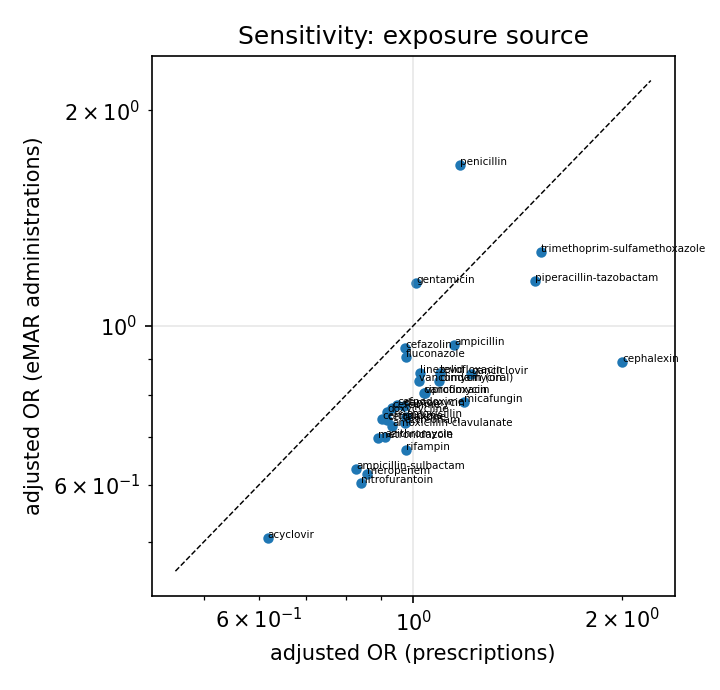

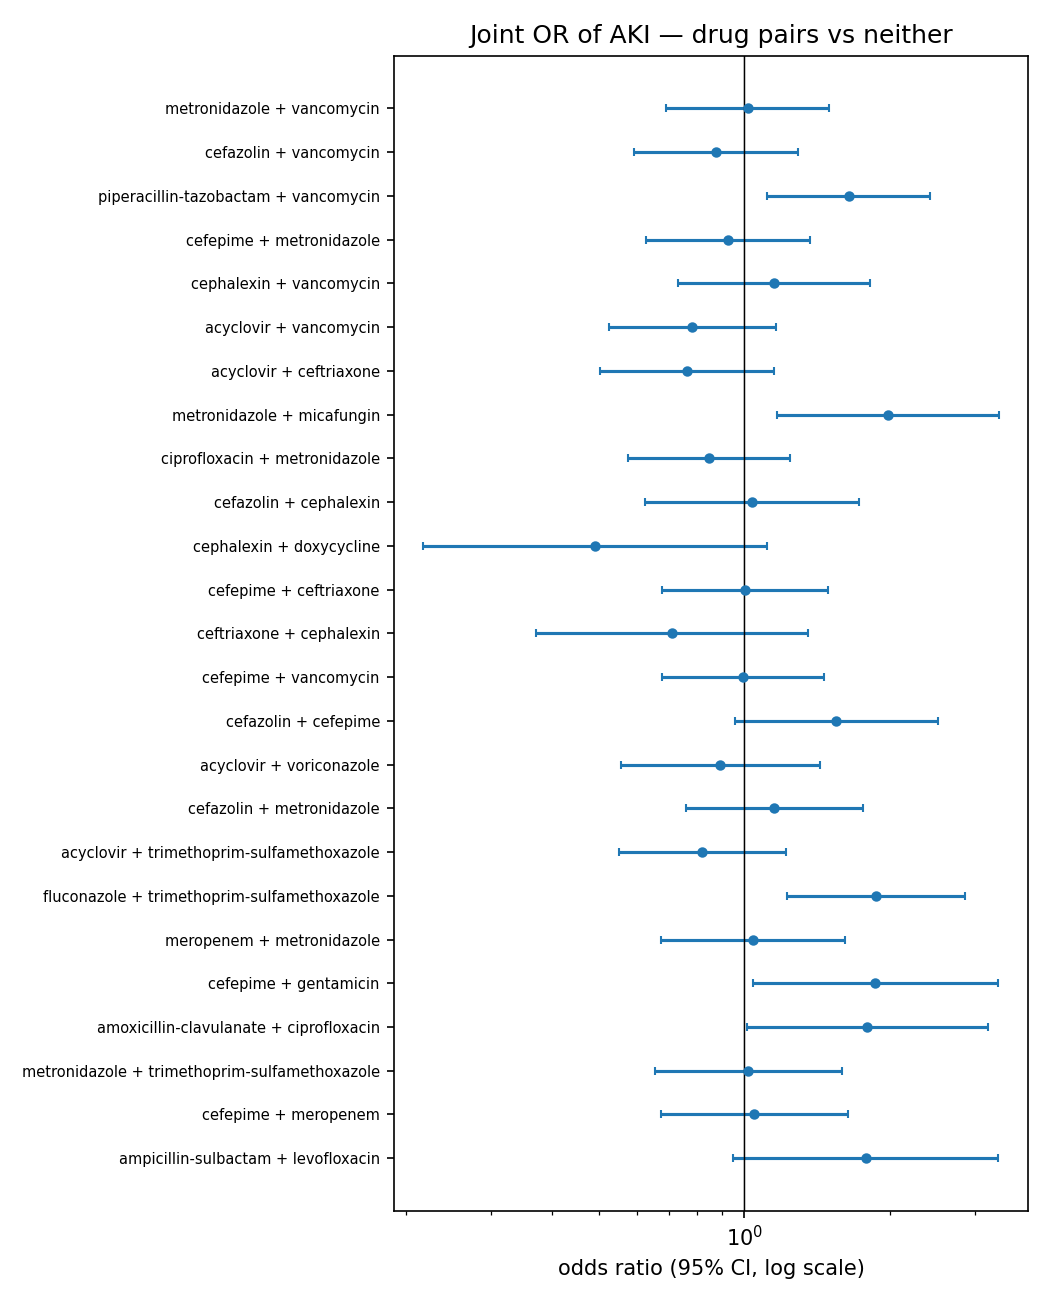

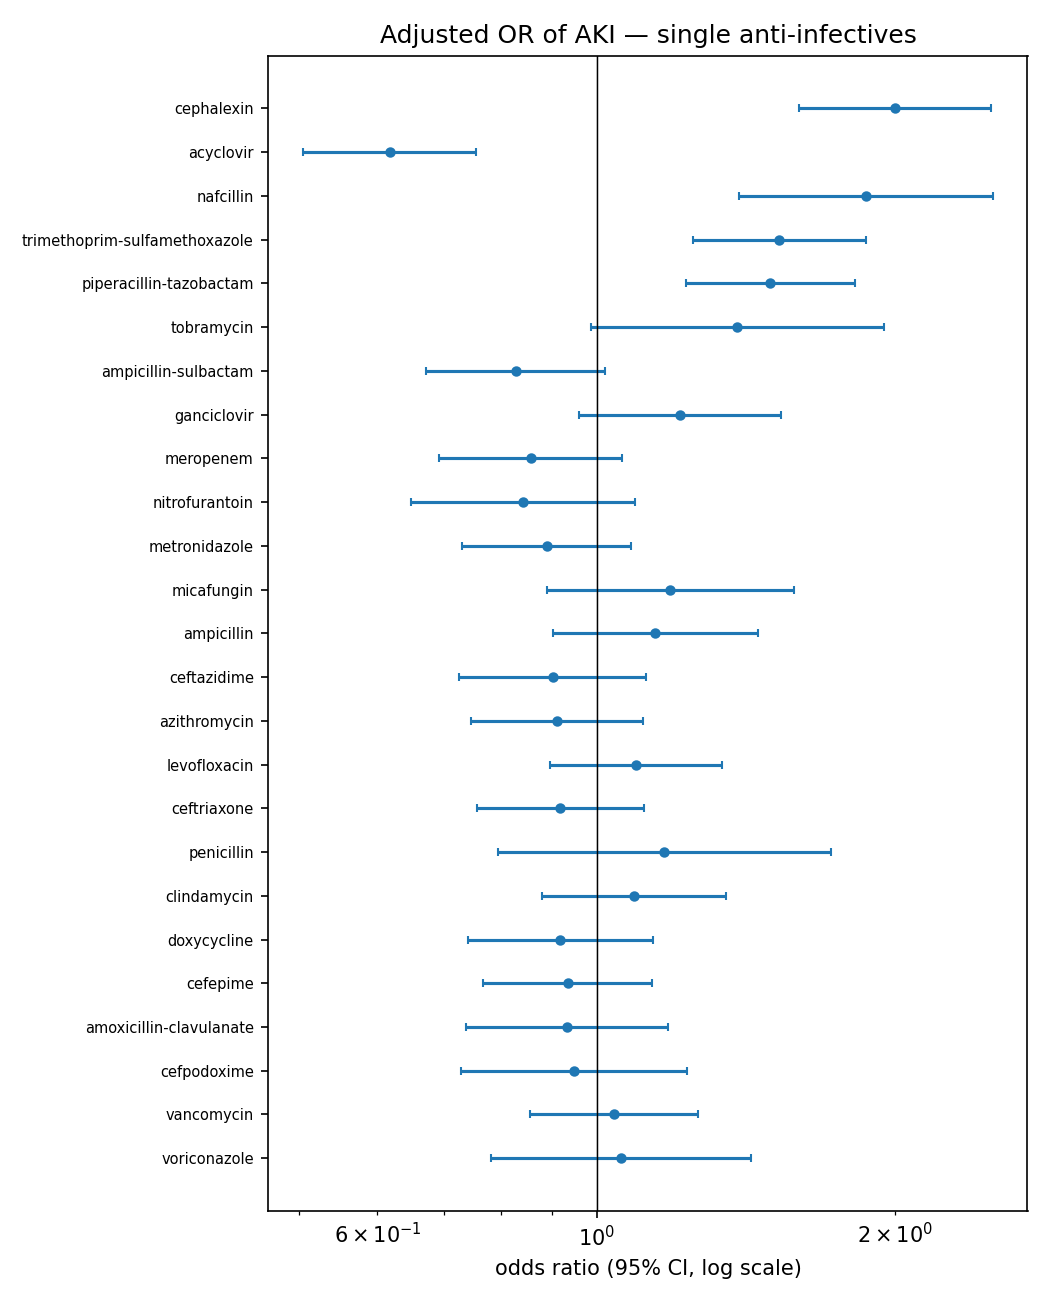

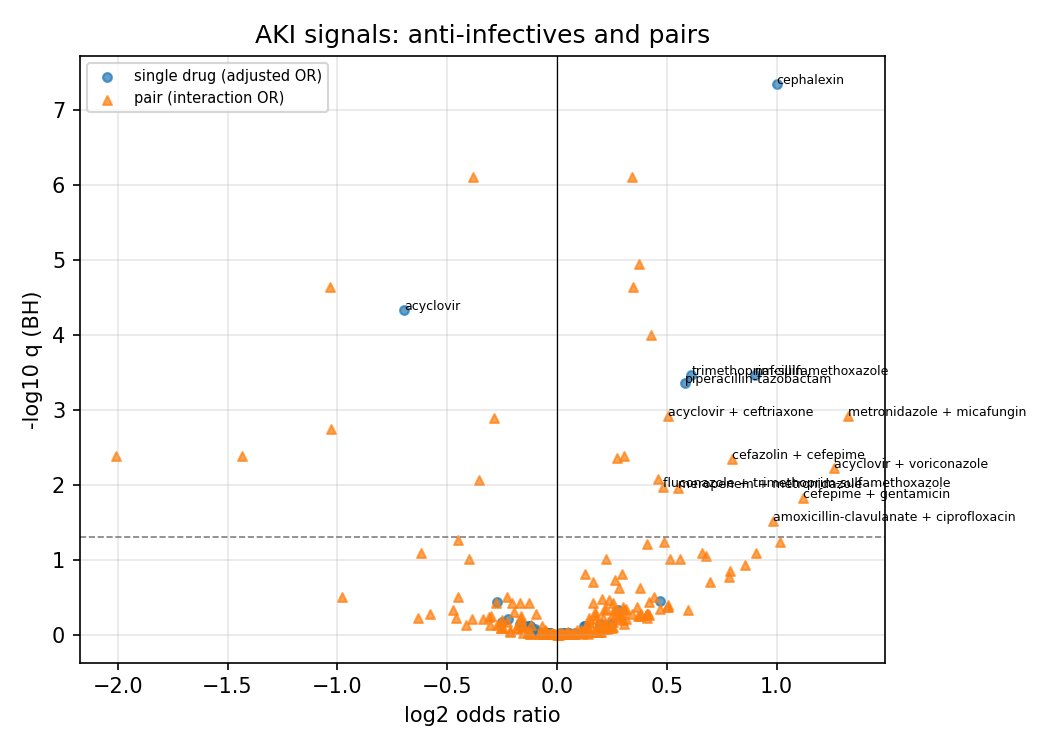

Results zip : /kaggle/working/results_for_github.zip  -> unzip into the repo as results/
Models (.pth, private — keep out of GitHub):
   /kaggle/working/aki/model/aki_signal_model.pth
Bucket copy : gs://mimic-cxr-training-mimic-ckpt/mimic-drug-aki-signals/runs/main/model/


In [29]:
import re, shutil, glob
from IPython.display import Markdown, Image, display
rep = f"{cfg.work_dir}/report"
text = open(f"{rep}/REPORT.md", encoding="utf-8").read()
display(Markdown(re.sub(r"!\[.*?\]\(figures/.*?\)", "", text)))
for f in sorted(glob.glob(f"{rep}/figures/*.png")):
    display(Image(f))
shutil.make_archive("/kaggle/working/results_for_github", "zip", rep)
print("Results zip : /kaggle/working/results_for_github.zip  -> unzip into the repo as results/")
print("Models (.pth, private — keep out of GitHub):")
for f in sorted(glob.glob(f"{cfg.work_dir}/model/*.pth")):
    print("  ", f)
print("Bucket copy :", "gs://" + cfg.bucket + "/" + cfg.gcs_prefix + "/runs/" + cfg.run_name + "/model/")